# Nordic berry habitat model (PyTorch)

Given a **location** in Finland or the Nordic region, this notebook fetches the **soil**, **climate**, **land cover / forest type**, **terrain** and **human footprint** there, and predicts how suitable the place is for each of **10 wild berry species**. One shared neural network learns from all species at once; each species has its own learned embedding.

| Species | Latin | Finnish |
|---|---|---|
| bilberry | *Vaccinium myrtillus* | mustikka |
| lingonberry | *Vaccinium vitis-idaea* | puolukka |
| cloudberry | *Rubus chamaemorus* | hilla |
| raspberry | *Rubus idaeus* | vadelma |
| bog bilberry | *Vaccinium uliginosum* | juolukka |
| cranberry | *Vaccinium oxycoccos* | karpalo |
| crowberry | *Empetrum nigrum* | variksenmarja |
| wild strawberry | *Fragaria vesca* | metsämansikka |
| arctic bramble | *Rubus arcticus* | mesimarja |
| sea buckthorn | *Hippophae rhamnoides* | tyrni |

Add more species by adding a line to the `SPECIES` dictionary (`resolve_taxon_key()` finds the GBIF key) and re-running.

### Read this before trusting any output

* **Two ways to get labels, chosen with `LABEL_MODE` in the setup cell.**
  * `"rules"` (default): every place in the combined table is labelled by a short script (section 4b, `label_dataset`) that encodes **literature-based "right conditions" per berry**. Where the conditions are right a berry is assumed present with **30 %** probability, and with **50 %** if the place is also **undisturbed** (no built-up surface nearby, little farmland); everywhere else 2 %. A label is then drawn at random from that probability. **These labels are assumptions written as rules, not observations.** A model trained on them learns the rules. Its held-out score measures how well it recovers the rules, and says nothing about berries in reality.
  * `"gbif"`: real presence-only sightings from GBIF against a target-group background (other plants recorded by the same observers, which cancels most "people record near roads" bias). Output is a relative suitability index, not a probability.
* **Reality check built in.** In `rules` mode the notebook still downloads the real GBIF records and (a) measures how well the rules agree with them and (b) scores the trained network against them on held-out blocks. If those numbers are near chance, the rules do not resemble where the species is actually recorded.
* **To get real probabilities and accuracy** you need true presence/absence or abundance records (for example the 1 m² plot surveys in the BerryFinder app, or Luke's monitoring plots if you obtain access). Section 11 calibrates the model with such data when you have it.
* Nothing in this notebook has been executed yet. Run it top to bottom on your server. `QUICK = True` gives a small end-to-end smoke test first.

## 0. Setup
Run once. On a GPU server install the CUDA build of PyTorch first (see pytorch.org), then the rest. The model is small (under 1 M parameters), so a CPU also works.

In [1]:
%pip install -q torch numpy pandas scikit-learn scipy requests matplotlib rasterio pyproj shapely pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import copy
import math
import random
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)

# ----------------------------------------------------------------- configuration
QUICK = False            # True = tiny sample, a few minutes: use it to smoke-test the whole pipeline first
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA = Path("data")
CACHE = DATA / "cache"          # every downloaded table is cached here, so a crashed run resumes where it stopped
ARTIFACTS = Path("artifacts")
for p in (DATA, CACHE, ARTIFACTS):
    p.mkdir(parents=True, exist_ok=True)

N_PRESENCE = 250 if QUICK else 3000     # max presence cells kept per species
N_BACKGROUND = 1500 if QUICK else 25000  # target-group background cells
CELL = 0.02                              # spatial thinning grid in degrees (about 1 to 2 km)
BLOCK_DEG = 1.0                          # spatial blocks for train / validation / test splits
MAX_UNCERTAINTY_M = 1000                 # drop records whose coordinates are less precise than this
LABEL_MODE = "rules"   # "rules": pseudo-labels from the labelling script in section 4b (written assumptions)  |  "gbif": real presence-only records vs a plant background

NORDIC_COUNTRIES = ["FI", "SE", "NO", "DK", "IS"]
REGIONS = [
    dict(west=3.0, south=54.5, east=32.0, north=71.5),     # Fennoscandia + Denmark
    dict(west=-25.0, south=63.0, east=-13.0, north=67.0),  # Iceland
]

# GBIF taxon keys (verified against api.gbif.org/v1/species/match)
SPECIES = {
    "bilberry":        dict(latin="Vaccinium myrtillus",    key=2882833, fi="mustikka"),
    "lingonberry":     dict(latin="Vaccinium vitis-idaea",  key=2882835, fi="puolukka"),
    "cloudberry":      dict(latin="Rubus chamaemorus",      key=2998290, fi="hilla"),
    "raspberry":       dict(latin="Rubus idaeus",           key=2993094, fi="vadelma"),
    "bog_bilberry":    dict(latin="Vaccinium uliginosum",   key=8073364, fi="juolukka"),
    "cranberry":       dict(latin="Vaccinium oxycoccos",    key=2882940, fi="karpalo"),
    "crowberry":       dict(latin="Empetrum nigrum",        key=8925249, fi="variksenmarja"),
    "wild_strawberry": dict(latin="Fragaria vesca",         key=3029817, fi="metsämansikka"),
    "arctic_bramble":  dict(latin="Rubus arcticus",         key=2992051, fi="mesimarja"),
    "sea_buckthorn":   dict(latin="Hippophae rhamnoides",   key=3039285, fi="tyrni"),
}
TRACHEOPHYTA_KEY = 7707728   # all vascular plants: the target-group background

session = requests.Session()
session.headers.update({"User-Agent": "NordicBerryHabitatNotebook/1.0 (research use; set your contact email here)"})


def http_get_json(url, params=None, tries=6, timeout=90):
    # GET with exponential backoff on throttling and server errors
    for attempt in range(tries):
        try:
            r = session.get(url, params=params, timeout=timeout)
            if r.status_code in (429, 500, 502, 503, 504):
                raise requests.HTTPError(f"HTTP {r.status_code}")
            r.raise_for_status()
            return r.json()
        except (requests.RequestException, ValueError):
            if attempt == tries - 1:
                raise
            time.sleep(min(60, 2 ** attempt + random.random()))


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
print("device:", DEVICE, "| QUICK:", QUICK)

device: cpu | QUICK: False


## 1. Which datasets, and why they relate to berry growth

Every variable below has a documented ecological link to where these berries grow. The notebook measures how strongly each one separates presence from background (section 5) instead of assuming it.

| Dataset | Variables used | Why it matters for berries | Coverage | Licence |
|---|---|---|---|---|
| **GBIF occurrences** | Presence points per species (human observations and specimens, 1990 to now, coordinate precision under 1 km) | Defines which places are in the table, the real labels in `gbif` mode, and the reality check in `rules` mode. Presence-only, so used with a target-group background | Nordic countries | Only CC0 and CC BY 4.0 records are requested |
| **CHELSA V2.1 climate normals 1981 to 2010** (about 1 km) | Monthly mean temperature, minimum temperature, precipitation and climate moisture index; season layers: growing degree days above 5 °C, growing-season length, **snow-cover days**, frost-change frequency | Heat sum and season length set flowering and ripening; snow cover insulates low shrubs from winter frost; deep cold and late frost limit bilberry; summer moisture matters for cloudberry and cranberry | Global, 30 arc-seconds (about 1 km), terrain-aware | CC0 1.0 (credit Karger et al. 2017, Scientific Data 4:170122) |
| **ISRIC SoilGrids 2.0** | Topsoil pH, soil organic carbon, nitrogen, sand, clay (5 to 15 cm) | *Vaccinium* and *Empetrum* need acid soils; organic carbon separates mineral heath from peat (cloudberry, cranberry, bog bilberry live on peat); texture sets drainage | Global, 250 m | CC BY 4.0 |
| **ESA WorldCover 2021** | Fractions of tree cover, shrub, grass, cropland, built-up, bare, water, wetland and moss within about 200 m | Forest versus mire versus open land and cultivated land | Global, 10 m | CC BY 4.0 |
| **Copernicus DEM GLO-30** (30 m) | Elevation, slope, aspect (northness and eastness), local position (valley or ridge, at about 100 m and 300 m) and relief within about 300 m | Cold-air pockets and wet hollows versus dry ridges; north-facing slopes hold snow and stay cool; elevation sets the tree line and season length | Global, 30 m | Copernicus DEM licence (free and open, credit ESA/Copernicus) |
| **ESA WorldCover 2021, wider window** | Share of tree cover, built-up and cropland within 500 m, and distance to the nearest built-up pixel | "Deep forest" versus edge and disturbed land. Built-up distance is only a **proxy** for roads (narrow forest roads are probably not visible at 10 m) | Global, 10 m | CC BY 4.0 |
| **Finnish Forest Centre stand data** (optional branch) | Site fertility class, mire or heath class, pine, spruce and broadleaf shares, age, basal area, height, volume, development class | The strongest forest-type signal for *Vaccinium* in Finland (mesic versus dry heath, stand age, canopy) | **Finland only** (masked elsewhere) | CC BY 4.0 |

**Not downloaded here, worth adding if you can get them:** national forest inventories from Luke (Finland), SLU (Sweden) and NIBIO SR16 (Norway) for Nordic-wide tree species; MODIS NDVI and snow-cover duration from NASA Earthdata (needs a login); Luke's berry monitoring plots (needs permission). NIST publishes no ecological data, so it is not used here.

### Where the label rules come from

The labelling script in section 4b holds one rule set per species. The papers behind it, found while preparing this notebook (read at abstract level, so treat the numbers as approximate):

* **Bilberry:** highest cover on mesic heath and fell forests and lower on peatland; mature pine stands yield about twice spruce stands (Miina, Hotanen & Salo 2009; Turtiainen et al. 2016, *Silva Fennica*).
* **Lingonberry:** abundance depends on site fertility and stand basal area (Turtiainen et al. 2013); acid, moist but well-drained podzols and cambisols (lingonberry review, *Notulae Scientia Biologicae*); *Vaccinium* are calcifuges (USDA Forest Service).
* **Cloudberry:** acidic, little-decomposed peat, pH about 3.5 to 4.5 and a water table 30 to 50 cm down (Latvian field study; Université Laval cultivation work).
* **Cranberry, bog bilberry, crowberry:** bogs and heaths on acid, nutrient-poor soil (EUNIS habitat descriptions).
* **Raspberry, arctic bramble:** open woods, clearings and man-made open ground; arctic bramble on coarse soil at pH 5 to 7 and avoiding oceanic climate (species profiles, University of Alberta ACRRE).
* **Forest interior versus edge:** a Karelian clear-cut ecotone study found the most bilberry and lingonberry, and the highest bilberry yield, in interior forest (citation details unverified), and a Swedish clear-cut survey found berry production peaking around eight years after felling. No study found isolates **roads**, so the "undisturbed = 50 %" bonus is an assumption.
* **Not found:** a usable source for wild strawberry or sea buckthorn habitat in the Nordics. Their rules are marked as assumptions in the file.

The thresholds themselves (for example "pH 3.5 to 5.6" or "at least 60 snow-cover days") are my reading of that literature, tagged `assumption` where no paper gives a number. Edit them in the labelling cell of section 4b, which also holds the full reference list.

**The 50 % rule and open-ground berries.** Applied literally to every species, "undisturbed" gets 50 %. That fits forest and bog berries, but raspberry, wild strawberry, arctic bramble and sea buckthorn like open or disturbed ground. `label_dataset(..., literal=False)` gives those four their 50 % on disturbed, open or edge land instead. The default follows the rule as specified.

## 2. Presence records from GBIF

The Nordic region is cut into 4° by 2° tiles. For each species the notebook counts records per tile, then reads random result pages from each tile in proportion to its count. This spreads the sample over the whole region instead of taking only the first records GBIF returns. Records are thinned to one per species per 0.02° cell.

In [3]:
GBIF_SEARCH = "https://api.gbif.org/v1/occurrence/search"
LICENSES = ["CC0_1_0", "CC_BY_4_0"]
BASIS = ["HUMAN_OBSERVATION", "PRESERVED_SPECIMEN"]
PAGE = 300            # GBIF maximum page size
MAX_OFFSET = 99_000   # GBIF refuses offset + limit above 100,000


def make_tiles(dlon=4.0, dlat=2.0):
    tiles = []
    for region in REGIONS:
        lon = region["west"]
        while lon < region["east"]:
            lat = region["south"]
            while lat < region["north"]:
                tiles.append((lon, lat, min(lon + dlon, region["east"]), min(lat + dlat, region["north"])))
                lat += dlat
            lon += dlon
    return tiles


def gbif_params(taxon_key, tile):
    west, south, east, north = tile
    wkt = f"POLYGON(({west} {south},{east} {south},{east} {north},{west} {north},{west} {south}))"   # counter-clockwise
    params = [("taxonKey", taxon_key), ("hasCoordinate", "true"), ("hasGeospatialIssue", "false"),
              ("occurrenceStatus", "PRESENT"), ("year", f"1990,{datetime.now().year}"), ("geometry", wkt)]
    params += [("license", x) for x in LICENSES]
    params += [("country", c) for c in NORDIC_COUNTRIES]
    params += [("basisOfRecord", b) for b in BASIS]
    return params


def gbif_count(taxon_key, tile):
    return http_get_json(GBIF_SEARCH, gbif_params(taxon_key, tile) + [("limit", 0)])["count"]


def gbif_page(taxon_key, tile, offset):
    return http_get_json(GBIF_SEARCH, gbif_params(taxon_key, tile) + [("limit", PAGE), ("offset", offset)])["results"]


def parse_gbif(r):
    return dict(gbif_id=r.get("key"), lat=r.get("decimalLatitude"), lon=r.get("decimalLongitude"),
                unc=r.get("coordinateUncertaintyInMeters"), year=r.get("year"), country=r.get("countryCode"),
                dataset=r.get("datasetKey"), license=r.get("license"))


def to_cells(df):
    df = df.copy()
    df["ci"] = np.floor(df["lat"] / CELL).astype(int)
    df["cj"] = np.floor(df["lon"] / CELL).astype(int)
    return df


def fetch_taxon(taxon_key, quota, rng, oversample=1.6, workers=4):
    tiles = make_tiles()
    with ThreadPoolExecutor(workers) as ex:
        counts = np.array(list(ex.map(lambda t: gbif_count(taxon_key, t), tiles)))
    counts = np.minimum(counts, MAX_OFFSET)
    if counts.sum() == 0:
        return pd.DataFrame(columns=["gbif_id", "lat", "lon", "unc", "year", "country", "dataset", "license", "ci", "cj"])
    jobs = []
    for tile, c in zip(tiles, counts):
        if c == 0:
            continue
        want = quota * oversample * c / counts.sum()
        pages_available = max(1, math.ceil(c / PAGE))
        n_pages = min(pages_available, max(1, math.ceil(want / PAGE)))
        offsets = rng.choice(pages_available, size=n_pages, replace=False) * PAGE
        jobs += [(tile, int(o)) for o in offsets]
    with ThreadPoolExecutor(workers) as ex:
        pages = list(ex.map(lambda job: gbif_page(taxon_key, job[0], job[1]), jobs))
    rows = [parse_gbif(r) for page in pages for r in page]
    if not rows:
        return pd.DataFrame(columns=["gbif_id", "lat", "lon", "unc", "year", "country", "dataset", "license", "ci", "cj"])
    df = pd.DataFrame(rows)
    df = df.dropna(subset=["lat", "lon"]).drop_duplicates("gbif_id")
    df = df[df["unc"].notna() & (df["unc"] <= MAX_UNCERTAINTY_M)]
    df = to_cells(df).sample(frac=1.0, random_state=int(rng.integers(1_000_000)))   # shuffle, then keep one per cell
    df = df.drop_duplicates(["ci", "cj"])
    return df.head(quota).reset_index(drop=True)


def resolve_taxon_key(scientific_name):
    # helper for adding a species: print the key and paste it into SPECIES
    m = http_get_json("https://api.gbif.org/v1/species/match", {"name": scientific_name, "kingdom": "Plantae"})
    print(scientific_name, "->", m.get("usageKey"), m.get("matchType"), m.get("status"))
    return m.get("usageKey")

In [4]:
presence_file = DATA / "presence.parquet"
if presence_file.exists():
    presence = pd.read_parquet(presence_file)
else:
    rng = np.random.default_rng(SEED)
    parts = []
    for name, meta in SPECIES.items():
        d = fetch_taxon(meta["key"], N_PRESENCE, rng)
        d["species"] = name
        parts.append(d)
        print(f"{name:16s} {len(d):6d} presence cells")
    presence = pd.concat(parts, ignore_index=True)
    presence.to_parquet(presence_file)

print(presence.groupby("species").size().sort_values())

bilberry           3000 presence cells
lingonberry        3000 presence cells
cloudberry         3000 presence cells
raspberry          3000 presence cells
bog_bilberry       3000 presence cells
cranberry          3000 presence cells
crowberry          3000 presence cells
wild_strawberry    3000 presence cells
arctic_bramble     3000 presence cells
sea_buckthorn      2473 presence cells
species
sea_buckthorn      2473
arctic_bramble     3000
bog_bilberry       3000
bilberry           3000
cranberry          3000
crowberry          3000
lingonberry        3000
cloudberry         3000
raspberry          3000
wild_strawberry    3000
dtype: int64


### Target-group background

Background points are **other vascular plants recorded in the same countries by the same kind of observers**. If berries look "common near roads", so do the background plants, so the model cannot score well just by learning where people walk. These points are treated as *unlabelled*, not as true absences.

In [5]:
background_file = DATA / "background.parquet"
if background_file.exists():
    background = pd.read_parquet(background_file)
else:
    rng = np.random.default_rng(SEED + 1)
    background = fetch_taxon(TRACHEOPHYTA_KEY, N_BACKGROUND, rng, oversample=2.5)
    background.to_parquet(background_file)
print(len(background), "background cells")

16155 background cells


## 3. One table, one row per place, one column per berry

Presence and background cells are merged on the grid cell. These are the **real GBIF labels** (`gbif_y_<species>`; section 4b decides whether they or rule labels become the training labels `y_<species>`). For each berry the GBIF value is

* `1` the species was recorded in that cell,
* `0` the cell is a background cell and the species was not recorded there,
* `-1` unknown. A cell known only because *another* berry was recorded there says nothing about this one, so it is **masked out of that species' loss**.

Rows are then assigned to **train / validation / test by 1° geographic blocks**, so a test place is never next to a training place.

In [6]:
SPECIES_NAMES = list(SPECIES)


def build_master(presence, background):
    pres = presence[["ci", "cj", "species"]].drop_duplicates()
    flags = pres.assign(v=1).pivot_table(index=["ci", "cj"], columns="species", values="v", aggfunc="max")
    flags = flags.reindex(columns=SPECIES_NAMES)
    bg_index = pd.MultiIndex.from_frame(background[["ci", "cj"]].drop_duplicates())
    index = flags.index.union(bg_index)
    flags = flags.reindex(index)

    pos = flags.notna().to_numpy()
    y = np.full(pos.shape, -1, dtype=np.int8)
    y[index.isin(bg_index), :] = 0
    y[pos] = 1

    meta = pd.DataFrame(index=index).reset_index()
    meta["lat"] = (meta["ci"] + 0.5) * CELL
    meta["lon"] = (meta["cj"] + 0.5) * CELL
    country = (pd.concat([presence[["ci", "cj", "country"]], background[["ci", "cj", "country"]]])
               .drop_duplicates(["ci", "cj"]).set_index(["ci", "cj"])["country"])
    meta["country"] = country.reindex(index).to_numpy()
    labels = pd.DataFrame(y, columns=[f"gbif_y_{s}" for s in SPECIES_NAMES])
    return pd.concat([meta, labels], axis=1)


def assign_splits(df, seed=SEED, fractions=(0.70, 0.15, 0.15)):
    df = df.copy()
    df["block"] = (np.floor(df["lat"] / BLOCK_DEG).astype(int).astype(str) + "_" + np.floor(df["lon"] / BLOCK_DEG).astype(int).astype(str))
    blocks = np.array(sorted(df["block"].unique()))
    np.random.default_rng(seed).shuffle(blocks)
    n_train = int(len(blocks) * fractions[0])
    n_val = int(len(blocks) * fractions[1])
    split_of = {}
    for i, b in enumerate(blocks):
        split_of[b] = "train" if i < n_train else ("val" if i < n_train + n_val else "test")
    df["split"] = df["block"].map(split_of)
    return df


master = assign_splits(build_master(presence, background))
print(master["split"].value_counts().to_dict())
summary = pd.DataFrame({
    s: {sp: int((master.loc[master["split"] == sp, f"gbif_y_{s}"] == 1).sum()) for sp in ["train", "val", "test"]}
    for s in SPECIES_NAMES}).T
summary["background"] = int((master[[f"gbif_y_{s}" for s in SPECIES_NAMES]].max(axis=1) == 0).sum())
display(summary)
if (summary[["val", "test"]] < 20).any().any():
    print("WARNING: some species have fewer than 20 presences in validation or test. Raise N_PRESENCE or change BLOCK_DEG.")

{'train': 26423, 'test': 6254, 'val': 4756}


,train,val,test,background
bilberry,2019,388,593,13210
lingonberry,2005,331,664,13210
cloudberry,2008,480,512,13210
raspberry,2048,389,563,13210
bog_bilberry,2042,457,501,13210
cranberry,2200,361,439,13210
crowberry,2025,398,577,13210
wild_strawberry,2201,407,392,13210
arctic_bramble,2357,305,338,13210
sea_buckthorn,1599,211,663,13210


## 4. Environmental features for every place

Each source is fetched **once per place**, cached to `data/cache/`, and resumes after a crash. Soil and land cover are read straight from cloud-optimised rasters over HTTP, so nothing large is downloaded. The climate and soil steps are the slow ones (many small reads from cloud files); run them with the default thread counts and leave them.

The same functions are used later to build features for a **single location** or a **map grid** at prediction time.

In [7]:
import rasterio
from pyproj import Transformer
from rasterio.windows import Window

MONTHS = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]

# settings for reading cloud-optimised GeoTIFFs over HTTP (climate, soil and land cover all use them)
GDAL_ENV = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.vrt,.tiff",
                GDAL_HTTP_MAX_RETRY="6", GDAL_HTTP_RETRY_DELAY="2", VSI_CACHE="TRUE", VSI_CACHE_SIZE="268435456",
                CPL_VSIL_CURL_CACHE_SIZE="268435456")


def key_of(points):
    return points["lat"].round(5).map("{:.5f}".format) + "_" + points["lon"].round(5).map("{:.5f}".format)


def cached_table(name, points, compute, chunk=3000):
    # compute(points_df) -> DataFrame with one row per input row. Results are appended to a parquet cache chunk by chunk.
    path = CACHE / f"{name}.parquet"
    keys = key_of(points)
    cache = pd.read_parquet(path) if path.exists() else None
    missing = pd.Series(True, index=keys.index) if cache is None else ~keys.isin(cache.index)
    if missing.any():
        todo = points.loc[missing, ["lat", "lon"]].copy()
        todo["key"] = keys[missing]
        todo = todo.drop_duplicates("key").reset_index(drop=True)
        for start in range(0, len(todo), chunk):
            part = todo.iloc[start:start + chunk].reset_index(drop=True)
            new = compute(part[["lat", "lon"]])
            new.index = part["key"].to_numpy()
            cache = new if cache is None else pd.concat([cache, new])
            cache.to_parquet(path)
            print(f"  {name}: {min(start + chunk, len(todo))}/{len(todo)} new places")
    out = cache.reindex(keys.to_numpy())
    out.index = points.index
    return out

### 4.1 Climate: CHELSA V2.1 normals at about 1 km

CHELSA (Karger et al. 2017, CC0) downscales climate reanalysis with terrain, so it separates a river valley from the fell above it, which a 55 km grid cannot. Everything is a **1981 to 2010 normal** on a 30 arc-second grid (about 1 km), read from cloud-optimised GeoTIFFs:

* **12-month sequences:** mean temperature, minimum temperature, precipitation and the climate moisture index (rain minus evaporative demand; negative means water deficit).
* **Season layers computed by CHELSA itself:** growing degree days above 5 °C, growing-season length, **snow-cover days** and frost-change frequency. Snow cover insulates the low shrubs (bilberry, lingonberry, crowberry) from winter frost, and growing-season length decides whether fruit can ripen, so these are some of the most relevant climate variables for berries.

In [8]:
CHELSA = "/vsicurl/https://os.unil.cloud.switch.ch/chelsa02/chelsa/global/"
CLIM_CHANNELS = ["tas", "tasmin", "pr", "cmi"]     # monthly: mean temp (C), minimum temp (C), precipitation (mm), climate moisture index
CHELSA_BIO = ["gdd5", "gsl", "scd", "fcf"]         # degree-days above 5 C, growing season length (days), snow cover days, frost change frequency
CLIM_WORKERS = 12
CLIM_SUBCHUNK = 2000


def chelsa_url(var, month=None):
    if month is None:
        return f"{CHELSA}bioclim/{var}/1981-2010/CHELSA_{var}_1981-2010_V.2.1.tif"
    return f"{CHELSA}climatologies/{var}/1981-2010/CHELSA_{var}_{month:02d}_1981-2010_V.2.1.tif"


def month_cols(param):
    return [f"{param}_{m}" for m in MONTHS]


def _chelsa_task(name, url, lons, lats, idx, kelvin):
    for attempt in range(4):
        try:
            with rasterio.Env(**GDAL_ENV):
                with rasterio.open(url) as ds:
                    vals = np.array([v[0] for v in ds.sample(zip(lons, lats))], dtype="float64")
                    nodata, scale, offset = ds.nodata, ds.scales[0], ds.offsets[0]
            if nodata is not None:
                vals[vals == nodata] = np.nan
            vals = vals * scale + offset              # CHELSA stores integers with a scale factor (temperatures in kelvin)
            return name, idx, (vals - 273.15 if kelvin else vals)
        except Exception as e:
            if attempt == 3:
                print("climate read failed for", name, str(e)[:120])
                return name, idx, np.full(len(idx), np.nan)
            time.sleep(5 * (attempt + 1))


def fetch_climate(points):
    lons, lats = points["lon"].to_numpy(), points["lat"].to_numpy()
    order = np.lexsort((lons, lats))               # sort so neighbouring places share raster blocks
    layers = [(f"{v}_{MONTHS[m - 1]}", chelsa_url(v, m), v in ("tas", "tasmin")) for v in CLIM_CHANNELS for m in range(1, 13)]
    layers += [(v, chelsa_url(v), False) for v in CHELSA_BIO]
    out = {name: np.full(len(points), np.nan) for name, _, _ in layers}
    with ThreadPoolExecutor(CLIM_WORKERS) as ex:
        futures = [ex.submit(_chelsa_task, name, url, lons[order[s:s + CLIM_SUBCHUNK]], lats[order[s:s + CLIM_SUBCHUNK]],
                             order[s:s + CLIM_SUBCHUNK], kelvin)
                   for name, url, kelvin in layers for s in range(0, len(order), CLIM_SUBCHUNK)]
        for f in futures:
            name, idx, vals = f.result()
            out[name][idx] = vals
    return pd.DataFrame(out)


# summary features: computed from the monthly normals, plus CHELSA's own season layers (already columns of the climate table)
CLIM_DER_COLS = ["t_ann", "t_cold", "t_warm", "t_range", "t_min_cold", "precip_ann", "precip_summer", "precip_winter", "cmi_summer",
                 "gdd5", "gsl", "scd", "fcf"]


def derive_climate(w):
    T = w[month_cols("tas")].to_numpy(float)
    Tmin = w[month_cols("tasmin")].to_numpy(float)
    P = w[month_cols("pr")].to_numpy(float)
    cmi = w[month_cols("cmi")].to_numpy(float)
    out = pd.DataFrame(index=w.index)
    out["t_ann"] = T.mean(1)
    out["t_cold"] = T.min(1)
    out["t_warm"] = T.max(1)
    out["t_range"] = out["t_warm"] - out["t_cold"]        # continentality
    out["t_min_cold"] = Tmin.min(1)                        # winter cold extreme
    out["precip_ann"] = P.sum(1)
    out["precip_summer"] = P[:, 5:8].sum(1)
    out["precip_winter"] = P[:, [11, 0, 1]].sum(1)
    out["cmi_summer"] = cmi[:, 5:8].mean(1)
    return out

### 4.2 Terrain, 4.3 Soil, 4.4 Land cover and disturbance, 4.5 Finnish stand data

**Terrain** is computed from a 21 x 21 window of the 30 m Copernicus DEM around each place: elevation, **slope**, **northness and eastness** (which way the slope faces; north-facing ground holds snow and stays cool), **local position** (below the surroundings = a hollow where cold air and water collect, above = a ridge, at about 100 m and 300 m) and **relief**. These capture microclimate that a 1 km climate grid cannot see.

In [9]:
# ------------------------------------------------------------ terrain (Copernicus DEM GLO-30, 30 m) and microclimate indices
DEM_BASE = "/vsicurl/https://copernicus-dem-30m.s3.amazonaws.com/"
TOPO_COLS = ["elevation", "slope", "northness", "eastness", "tpi_local", "tpi_broad", "relief"]


def terrain_indices(a, dx, dy, r, c):
    """a: elevation window in metres (rows run south, columns run east); (r, c): the place inside it; dx and dy: cell size in metres.

    Returns, in TOPO_COLS order: elevation, slope (degrees), northness and eastness (cosine and sine of the direction the slope
    faces, measured clockwise from north; 0 on flat ground), tpi_local (elevation minus the mean of the ~200 m neighbourhood;
    negative in a hollow, positive on a ridge), tpi_broad (same for the whole window, ~600 m) and relief (max minus min).
    """
    gy, gx = np.gradient(a, dy, dx)                     # gy: change per metre going south, gx: change per metre going east
    centre_rows, centre_cols = slice(max(r - 2, 0), r + 3), slice(max(c - 2, 0), c + 3)
    gx_c, gy_c = np.nanmean(gx[centre_rows, centre_cols]), np.nanmean(gy[centre_rows, centre_cols])
    slope = math.degrees(math.atan(math.hypot(gx_c, gy_c)))
    if slope >= 1.0:
        aspect = math.atan2(-gx_c, gy_c)                # downhill east = -gx, downhill north = +gy (rows run south)
        northness, eastness = math.cos(aspect), math.sin(aspect)
    else:
        northness = eastness = 0.0                      # flat ground has no aspect
    centre = a[r, c]
    local = a[max(r - 3, 0):r + 4, max(c - 3, 0):c + 4]
    return [centre, slope, northness, eastness, centre - np.nanmean(local), centre - np.nanmean(a), np.nanmax(a) - np.nanmin(a)]

DEM_HALF = 10        # a 21 x 21 cell window, about 600 m across
DEM_WORKERS = 8


def dem_url(lat, lon):
    la, lo = math.floor(lat), math.floor(lon)
    name = f"Copernicus_DSM_COG_10_{'N' if la >= 0 else 'S'}{abs(la):02d}_00_{'E' if lo >= 0 else 'W'}{abs(lo):03d}_00_DEM"
    return f"{DEM_BASE}{name}/{name}.tif"


def _terrain_tile_task(url, lats, lons, positions):
    out = np.full((len(lats), len(TOPO_COLS)), np.nan)
    try:
        with rasterio.Env(**GDAL_ENV):
            with rasterio.open(url) as ds:
                dy = abs(ds.res[1]) * 111320.0
                for k, (la, lo) in enumerate(zip(lats, lons)):
                    r, c = ds.index(lo, la)
                    r0, c0 = max(r - DEM_HALF, 0), max(c - DEM_HALF, 0)
                    r1, c1 = min(r + DEM_HALF + 1, ds.height), min(c + DEM_HALF + 1, ds.width)
                    if r1 - r0 < 7 or c1 - c0 < 7:
                        continue
                    a = ds.read(1, window=Window(c0, r0, c1 - c0, r1 - r0)).astype("float64")
                    dx = abs(ds.res[0]) * 111320.0 * math.cos(math.radians(la))
                    out[k] = terrain_indices(a, dx, dy, r - r0, c - c0)
    except rasterio.errors.RasterioIOError:
        pass     # no DEM tile here (open sea): leave NaN
    return positions, out


def fetch_terrain(points):
    lats, lons = points["lat"].to_numpy(), points["lon"].to_numpy()
    urls = [dem_url(la, lo) for la, lo in zip(lats, lons)]
    res = np.full((len(points), len(TOPO_COLS)), np.nan)
    groups = pd.Series(range(len(points))).groupby(urls)
    with ThreadPoolExecutor(DEM_WORKERS) as ex:
        futures = [ex.submit(_terrain_tile_task, u, lats[g.to_numpy()], lons[g.to_numpy()], g.to_numpy()) for u, g in groups]
        for f in futures:
            pos, out = f.result()
            res[pos] = out
    return pd.DataFrame(res, columns=TOPO_COLS)


# ------------------------------------------------------------ soil (ISRIC SoilGrids 2.0, read from cloud rasters)
SOIL_DEPTH = "5-15cm"
SOIL_PROPS = {            # SoilGrids property -> (column name, factor to convert stored integers to natural units)
    "phh2o":    ("ph", 0.1),          # pH x10
    "soc":      ("soc", 0.1),         # dg/kg -> g/kg
    "nitrogen": ("nitrogen", 0.01),   # cg/kg -> g/kg
    "sand":     ("sand", 0.1),        # g/kg -> %
    "clay":     ("clay", 0.1),        # g/kg -> %
}
SOIL_COLS = [v[0] for v in SOIL_PROPS.values()]
SOIL_WORKERS = 10
SOIL_SUBCHUNK = 500


def _soil_task(prop, lons, lats, idx):
    url = f"/vsicurl/https://files.isric.org/soilgrids/latest/data/{prop}/{prop}_{SOIL_DEPTH}_mean.vrt"
    for attempt in range(4):
        try:
            with rasterio.Env(**GDAL_ENV):
                with rasterio.open(url) as ds:
                    xs, ys = Transformer.from_crs("EPSG:4326", ds.crs, always_xy=True).transform(lons, lats)
                    vals = np.array([v[0] for v in ds.sample(zip(xs, ys))], dtype="float64")
                    nodata = ds.nodata
            if nodata is not None:
                vals[vals == nodata] = np.nan
            return prop, idx, vals * SOIL_PROPS[prop][1]
        except Exception as e:
            if attempt == 3:
                print("soil read failed for", prop, str(e)[:120])
                return prop, idx, np.full(len(idx), np.nan)
            time.sleep(5 * (attempt + 1))


def fetch_soil(points):
    lons, lats = points["lon"].to_numpy(), points["lat"].to_numpy()
    order = np.lexsort((lons, lats))         # neighbouring places share raster blocks, so sort for fewer requests
    out = {p: np.full(len(points), np.nan) for p in SOIL_PROPS}
    with ThreadPoolExecutor(SOIL_WORKERS) as ex:
        futures = [ex.submit(_soil_task, prop, lons[order[s:s + SOIL_SUBCHUNK]], lats[order[s:s + SOIL_SUBCHUNK]], order[s:s + SOIL_SUBCHUNK])
                   for prop in SOIL_PROPS for s in range(0, len(order), SOIL_SUBCHUNK)]
        for f in futures:
            prop, idx, vals = f.result()
            out[prop][idx] = vals
    return pd.DataFrame({SOIL_PROPS[p][0]: out[p] for p in SOIL_PROPS})


# ------------------------------------------------------------ land cover / forest type (ESA WorldCover 2021, 10 m)
WC_BASE = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/"
WC_CLASS = {10: "lc_tree", 20: "lc_shrub", 30: "lc_grass", 40: "lc_crop", 50: "lc_built", 60: "lc_bare", 70: "lc_bare",
            80: "lc_water", 90: "lc_wetland", 95: "lc_wetland", 100: "lc_moss"}
LC_COLS = ["lc_tree", "lc_shrub", "lc_grass", "lc_crop", "lc_built", "lc_bare", "lc_water", "lc_wetland", "lc_moss"]
WC_HALF = 10      # 21 x 21 pixels = about 210 m window
WC_WORKERS = 8


def wc_tile_name(lat, lon):
    la, lo = int(math.floor(lat / 3) * 3), int(math.floor(lon / 3) * 3)
    return f"ESA_WorldCover_10m_2021_v200_{'N' if la >= 0 else 'S'}{abs(la):02d}{'E' if lo >= 0 else 'W'}{abs(lo):03d}_Map.tif"


def _lc_tile_task(tile, lats, lons, positions):
    out = np.full((len(lats), len(LC_COLS)), np.nan)
    try:
        with rasterio.Env(**GDAL_ENV):
            with rasterio.open(f"/vsicurl/{WC_BASE}{tile}") as ds:
                for k, (la, lo) in enumerate(zip(lats, lons)):
                    r, c = ds.index(lo, la)
                    r0, c0 = max(r - WC_HALF, 0), max(c - WC_HALF, 0)
                    r1, c1 = min(r + WC_HALF + 1, ds.height), min(c + WC_HALF + 1, ds.width)
                    if r1 <= r0 or c1 <= c0:
                        continue
                    a = ds.read(1, window=Window(c0, r0, c1 - c0, r1 - r0))
                    counts = dict.fromkeys(LC_COLS, 0.0)
                    for code, col in WC_CLASS.items():
                        counts[col] += float((a == code).sum())
                    out[k] = [counts[col] / a.size for col in LC_COLS]
    except rasterio.errors.RasterioIOError:
        pass     # no tile here (open sea): leave NaN
    return positions, out


def fetch_landcover(points):
    tiles = [wc_tile_name(la, lo) for la, lo in zip(points["lat"], points["lon"])]
    res = np.full((len(points), len(LC_COLS)), np.nan)
    groups = pd.Series(range(len(points))).groupby(tiles)
    with ThreadPoolExecutor(WC_WORKERS) as ex:
        futures = [ex.submit(_lc_tile_task, t, points["lat"].to_numpy()[g.to_numpy()], points["lon"].to_numpy()[g.to_numpy()], g.to_numpy())
                   for t, g in groups]
        for f in futures:
            pos, out = f.result()
            res[pos] = out
    return pd.DataFrame(res, columns=LC_COLS)


# ------------------------------------------------------------ human footprint within 500 m (ESA WorldCover, 10 m)
# Distance to the nearest built-up pixel (WorldCover class 50) is a PROXY for roads and buildings: narrow forest roads under
# canopy are probably not visible at 10 m. For true road geometry, load an OpenStreetMap road extract (Geofabrik) and replace this.
HUMAN_COLS = ["built_dist_m", "lc_tree_1km", "lc_built_1km", "lc_crop_1km"]
HUMAN_RADIUS_M = 500


def _human_tile_task(tile, lats, lons, positions):
    out = np.full((len(lats), len(HUMAN_COLS)), np.nan)
    try:
        with rasterio.Env(**GDAL_ENV):
            with rasterio.open(f"/vsicurl/{WC_BASE}{tile}") as ds:
                dy = abs(ds.res[1]) * 111320.0
                for k, (la, lo) in enumerate(zip(lats, lons)):
                    dx = abs(ds.res[0]) * 111320.0 * math.cos(math.radians(la))
                    half_r, half_c = int(round(HUMAN_RADIUS_M / dy)), int(round(HUMAN_RADIUS_M / dx))
                    r, c = ds.index(lo, la)
                    r0, c0 = max(r - half_r, 0), max(c - half_c, 0)
                    r1, c1 = min(r + half_r + 1, ds.height), min(c + half_c + 1, ds.width)
                    if r1 <= r0 or c1 <= c0:
                        continue
                    a = ds.read(1, window=Window(c0, r0, c1 - c0, r1 - r0))
                    rows, cols = np.nonzero(a == 50)
                    dist = float(HUMAN_RADIUS_M)
                    if rows.size:
                        dist = min(dist, float(np.sqrt(((rows + r0 - r) * dy) ** 2 + ((cols + c0 - c) * dx) ** 2).min()))
                    out[k] = [dist, (a == 10).mean(), (a == 50).mean(), (a == 40).mean()]
    except rasterio.errors.RasterioIOError:
        pass
    return positions, out


def fetch_disturbance(points):
    lats, lons = points["lat"].to_numpy(), points["lon"].to_numpy()
    tiles = [wc_tile_name(la, lo) for la, lo in zip(lats, lons)]
    res = np.full((len(points), len(HUMAN_COLS)), np.nan)
    groups = pd.Series(range(len(points))).groupby(tiles)
    with ThreadPoolExecutor(WC_WORKERS) as ex:
        futures = [ex.submit(_human_tile_task, t, lats[g.to_numpy()], lons[g.to_numpy()], g.to_numpy()) for t, g in groups]
        for f in futures:
            pos, out = f.result()
            res[pos] = out
    return pd.DataFrame(res, columns=HUMAN_COLS)


# ------------------------------------------------------------ Finnish Forest Centre stands (Finland only)
METSA_WFS = "https://avoin.metsakeskus.fi/rajapinnat/v2/stand/ows"
FI_BBOX = (19.0, 59.7, 31.7, 70.2)
FI_COLS = ["fi_fertility", "fi_site_main", "fi_prop_pine", "fi_prop_spruce", "fi_prop_other", "fi_age", "fi_basal_area", "fi_height", "fi_volume", "fi_dev_rank"]
DEV_RANK = {"A0": 0, "S0": 0.5, "T1": 1, "T2": 2, "Y1": 2, "02": 3, "03": 4, "04": 5, "05": 4.5, "ER": 4}
FI_WORKERS = 8


def _num(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return np.nan


def _fi_task(x, y):
    params = {"service": "WFS", "version": "2.0.0", "request": "GetFeature", "typeNames": "v2:stand", "outputFormat": "application/json",
              "srsName": "EPSG:3067", "bbox": f"{x - 1},{y - 1},{x + 1},{y + 1},EPSG:3067", "count": 1}
    try:
        feats = http_get_json(METSA_WFS, params, tries=3, timeout=30).get("features") or []
    except Exception:
        return None
    if not feats:
        return dict.fromkeys(FI_COLS, np.nan)
    p = feats[0]["properties"]
    return {"fi_fertility": _num(p.get("fertilityclass")), "fi_site_main": _num(p.get("subgroup")),
            "fi_prop_pine": _num(p.get("proportionpine")), "fi_prop_spruce": _num(p.get("proportionspruce")),
            "fi_prop_other": _num(p.get("proportionother")), "fi_age": _num(p.get("meanage")),
            "fi_basal_area": _num(p.get("basalarea")), "fi_height": _num(p.get("meanheight")),
            "fi_volume": _num(p.get("volume")), "fi_dev_rank": DEV_RANK.get(p.get("developmentclass"), np.nan)}


def fetch_finnish_forest(points):
    lon, lat = points["lon"].to_numpy(), points["lat"].to_numpy()
    inside = (lon >= FI_BBOX[0]) & (lat >= FI_BBOX[1]) & (lon <= FI_BBOX[2]) & (lat <= FI_BBOX[3])
    x, y = Transformer.from_crs("EPSG:4326", "EPSG:3067", always_xy=True).transform(lon, lat)    # transform up front (thread safety)
    rows = [dict.fromkeys(FI_COLS, np.nan) for _ in range(len(points))]
    todo = np.flatnonzero(inside)
    with ThreadPoolExecutor(FI_WORKERS) as ex:
        for i, r in zip(todo, ex.map(lambda i: _fi_task(x[i], y[i]), todo)):
            if r is not None:
                rows[i] = r
    return pd.DataFrame(rows, columns=FI_COLS)


def extract_all_features(points):
    # points: DataFrame with lat and lon. Returns raw features (NaN where a source has no data).
    pts = points[["lat", "lon"]].reset_index(drop=True)
    clim = cached_table("climate_chelsa", pts, fetch_climate, chunk=4000)
    parts = [pts, clim, derive_climate(clim),
             cached_table("terrain", pts, fetch_terrain, chunk=3000),
             cached_table("soil", pts, fetch_soil, chunk=3000),
             cached_table("landcover", pts, fetch_landcover, chunk=3000),
             cached_table("human", pts, fetch_disturbance, chunk=2000),
             cached_table("finnish_forest", pts, fetch_finnish_forest, chunk=3000)]
    return pd.concat(parts, axis=1)

In [10]:
dataset_file = DATA / "berry_dataset.parquet"
if dataset_file.exists():
    data = pd.read_parquet(dataset_file)
else:
    feats = extract_all_features(master[["lat", "lon"]])
    data = pd.concat([master, feats.drop(columns=["lat", "lon"])], axis=1)
    data.to_parquet(dataset_file)

# drop open water and places without climate data
keep = data["t_ann"].notna() & (data["lc_water"].fillna(0) < 0.95)
print(f"dropping {int((~keep).sum())} water or no-climate rows of {len(data)}")
data = data[keep].reset_index(drop=True)

missing = data[CLIM_DER_COLS + SOIL_COLS + LC_COLS + TOPO_COLS + HUMAN_COLS + FI_COLS].isna().mean().sort_values(ascending=False)
print("share of rows missing each feature (Finnish stand data is expected to be missing outside Finland):")
display(missing.head(15).to_frame("missing"))

  climate_chelsa: 4000/37433 new places
  climate_chelsa: 8000/37433 new places
  climate_chelsa: 12000/37433 new places
  climate_chelsa: 16000/37433 new places
  climate_chelsa: 20000/37433 new places
  climate_chelsa: 24000/37433 new places
  climate_chelsa: 28000/37433 new places
  climate_chelsa: 32000/37433 new places
  climate_chelsa: 36000/37433 new places
  climate_chelsa: 37433/37433 new places
  terrain: 3000/37433 new places
  terrain: 6000/37433 new places
  terrain: 9000/37433 new places
  terrain: 12000/37433 new places
  terrain: 15000/37433 new places
  terrain: 18000/37433 new places
  terrain: 21000/37433 new places
  terrain: 24000/37433 new places
  terrain: 27000/37433 new places
  terrain: 30000/37433 new places
  terrain: 33000/37433 new places
  terrain: 36000/37433 new places
  terrain: 37433/37433 new places
  soil: 3000/37433 new places
  soil: 6000/37433 new places
  soil: 9000/37433 new places
  soil: 12000/37433 new places
  soil: 15000/37433 new places
 

,missing
fi_dev_rank,0.788107
fi_age,0.762433
fi_basal_area,0.762433
fi_height,0.762433
fi_volume,0.762433
fi_prop_other,0.762374
fi_site_main,0.762374
fi_fertility,0.762374
fi_prop_pine,0.762374
fi_prop_spruce,0.762374


## 4b. Labels: rule-based pseudo-labels, with the real GBIF records kept for checking

`label_dataset()` goes through every row of the combined table and, for each berry, (1) checks that species' "right conditions" (soil, climate, land cover, terrain thresholds), (2) assigns probability **0.30** if they hold, **0.50** if the place is also undisturbed, **0.02** otherwise, and (3) draws a 0/1 label from that probability with a fixed seed.

The first cell below **is the labelling script**: edit the thresholds or the three probabilities there if you disagree with them. The cell after it prints every rule with the paper or assumption behind it. The cell after that shows, per species, how much of the table meets the conditions and how many positive labels result, and then checks the rules against the real GBIF sightings: an AUC near 0.5 means the rules look nothing like where the species is actually recorded; clearly above 0.5 means they capture part of the real pattern.

### The labelling script

Rule-based pseudo-labels for Nordic wild berries.

Goes through a combined environmental table (one row per place) and, for every berry, decides:

  1. Are the "right conditions" met?  (soil, climate, land cover, terrain thresholds, one rule set per species)
  2. If yes, a berry is assumed present with probability P_RIGHT (30 %).
  3. If the place is also undisturbed (no built-up or paved surface nearby, little farmland), the probability is
     raised to P_UNDISTURBED (50 %).  This is the assumption requested for this project.
  4. Everywhere else the probability is a small P_OTHER (2 %), so the labels are not perfectly deterministic.

A label is then drawn at random from that probability with a fixed seed, giving 0/1 labels for every row and species.

IMPORTANT: these are ASSUMPTIONS written down as rules, not observations. The thresholds are informed by the papers listed
in REFERENCES, but most numeric cut-offs are the author's reading of that literature, flagged "assumption" below.
A model trained on these labels learns the rules; it does not learn where berries actually grow. Check the result against
real records (the notebook compares it with GBIF) and replace the rules with field data when you have it.

In [11]:
P_RIGHT = 0.30            # probability of a berry where the species' conditions are right
P_UNDISTURBED = 0.50      # ... and the place is undisturbed (deep in forest, no roads or buildings nearby)
P_OTHER = 0.02            # everywhere else (set to 0.0 for fully deterministic labels)

BUILT_FREE_M = 500.0      # no built-up surface within this distance counts as undisturbed
CROP_MAX = 0.05           # at most 5 % cropland within about 1 km
OPEN_TREE_MAX = 0.60      # below this tree share (1 km) a place counts as open or edge land

REFERENCES = {
    "Miina2009": "Miina, Hotanen & Salo (2009), Silva Fennica, doi:10.14214/sf.181: bilberry abundance and yield in Finnish "
                 "mineral-soil forests; yield in mature pine stands about twice that of spruce stands. https://silvafennica.fi/pdf/181",
    "Turtiainen2013": "Turtiainen, Miina, Salo & Hotanen (2013), Silva Fennica: cowberry (lingonberry) cover and yield depend on "
                      "site fertility and stand basal area. https://silvafennica.fi/article/1005",
    "Turtiainen2016": "Turtiainen, Miina, Salo & Hotanen (2016), Silva Fennica: bilberry cover highest in mesic heath and fell "
                      "forests, lower on peatlands. https://silvafennica.fi/article/1573",
    "MiinaMgmt": "Miina, Bohlin, Lind et al., Silva Fennica article 10573: berry yields under forest management; lower removals "
                 "favour bilberry, higher removals lingonberry. https://silvafennica.fi/article/10573",
    "CloudberryLatvia": "Habitat characteristics and mineral nutrition of Rubus chamaemorus in Latvia (PMC): acidic, organic, "
                        "little-decomposed peat. https://www.ncbi.nlm.nih.gov/pmc/articles/PMC9920050/",
    "CloudberryLaval": "Bellemare et al. / Theroux Rancourt et al., Universite Laval: cloudberry substrate pH 3.5 to 4.5 and water "
                       "table 30 to 50 cm. https://www.gret-perg.ulaval.ca/fileadmin/Fichiers/centre_recherche/Bellemare_etal_MP_2009_02.pdf",
    "USFSEricaceae": "USDA Forest Service Ericaceae note: Vaccinium species are calcifuges on acid, well-drained, organic soils. "
                     "https://www.fs.usda.gov/Internet/FSE_DOCUMENTS/fseprd1181067.pdf",
    "LingonberryReview": "Review of environmental conditions for wild lingonberry (Notulae Scientia Biologicae): podzols and cambisols, "
                         "moist but well-drained acid soils. https://notulaebiologicae.ro/index.php/nsb/article/view/12149",
    "EUNISHeath": "EUNIS sub-boreal Vaccinium heaths: bilberry, cowberry and Empetrum heaths. https://eunis.eea.europa.eu/habitats/22639",
    "EUNISBog": "EUNIS raised bog: Vaccinium uliginosum, Empetrum nigrum and Rubus chamaemorus are diagnostic. "
                "https://eunis.eea.europa.eu/habitats/32002",
    "RubusIdaeus": "Rubus idaeus species profile (ACRRE, Univ. of Alberta): open woods, clearings and edges, early successional, "
                   "slightly acid to near-neutral. https://acrre.ualberta.ca/acrre/wp-content/uploads/sites/45/2018/04/Rubus_idaeus.pdf",
    "RubusArcticus": "Rubus arcticus species profile (ACRRE): coarse soils at pH 5 to 7, no shade tolerance, favours man-made open "
                     "habitats in Finland, avoids oceanic climate in Scandinavia. "
                     "https://acrre.ualberta.ca/acrre/wp-content/uploads/sites/45/2018/04//Rubus_arcticus.pdf",
    "EdgeEcotone": "Study of a bilberry pine forest and clear-cut ecotone: interior forest had the highest bilberry and lingonberry "
                   "abundance and yield, the edge zone significantly less (citation details not verified). "
                   "https://archivog.com/0033-9946/article/view/674478",
    "SLUClearcuts": "SLU thesis on 935 Swedish clear-cuts: berry production low on young cuts, peaking around year 8. "
                    "https://stud.epsilon.slu.se/13481/",
}


# ----------------------------------------------------------------------------------------------- rule building blocks
def between(col, lo, hi, ref, optional=False):
    return {"kind": "range", "col": col, "lo": lo, "hi": hi, "ref": ref, "optional": optional}


def at_least(col, lo, ref, optional=False):
    return between(col, lo, np.inf, ref, optional)


def at_most(col, hi, ref, optional=False):
    return between(col, -np.inf, hi, ref, optional)


def any_of(label, *conds, ref="assumption"):
    return {"kind": "any", "label": label, "conds": list(conds), "ref": ref}


# Column units: ph (pH in water), soc (g/kg), sand (%), lc_* (share 0-1 within about 200 m), lc_*_1km (share within 500 m),
# gdd5 (degree-days above 5 C), gsl (growing season days), scd (snow cover days), precip_ann (mm), t_range (C), elevation (m).
RULES = {
    "bilberry": dict(boost="undisturbed", conditions=[
        between("ph", 3.5, 5.6, "USFSEricaceae+assumption"),
        at_least("lc_tree", 0.40, "Turtiainen2016"),
        at_most("lc_wetland", 0.25, "Turtiainen2016"),
        at_least("gsl", 90, "assumption"),
        at_least("scd", 60, "assumption: snow cover shelters it from winter frost"),
        at_least("precip_ann", 450, "assumption"),
        between("fi_fertility", 2, 4, "Miina2009,Turtiainen2016: mesic heath (Finnish stand data only)", optional=True),
    ]),
    "lingonberry": dict(boost="undisturbed", conditions=[
        between("ph", 3.3, 5.6, "USFSEricaceae+LingonberryReview"),
        at_least("lc_tree", 0.20, "EUNISHeath"),
        at_most("lc_wetland", 0.30, "Turtiainen2013"),
        at_least("sand", 35, "LingonberryReview: well-drained coarse soils"),
        at_least("gsl", 80, "assumption"),
        at_least("precip_ann", 400, "assumption"),
        between("fi_fertility", 3, 5, "Turtiainen2013: drier heaths (Finnish stand data only)", optional=True),
    ]),
    "cloudberry": dict(boost="undisturbed", conditions=[
        between("ph", 3.2, 5.0, "CloudberryLaval (pH 3.5 to 4.5) plus margin"),
        any_of("acidic peat or bog", at_least("soc", 150, "CloudberryLatvia"), at_least("lc_wetland", 0.35, "EUNISBog")),
        between("gdd5", 300, 1500, "assumption: circumboreal, scarce in the warm south"),
        at_least("scd", 100, "assumption"),
        at_least("precip_ann", 450, "assumption"),
    ]),
    "cranberry": dict(boost="undisturbed", conditions=[
        between("ph", 3.0, 5.0, "EUNISBog"),
        any_of("bog or wet peat", at_least("soc", 150, "EUNISBog"), at_least("lc_wetland", 0.30, "EUNISBog")),
        at_least("gsl", 90, "assumption"),
        at_least("precip_ann", 450, "assumption"),
    ]),
    "bog_bilberry": dict(boost="undisturbed", conditions=[
        between("ph", 3.0, 5.2, "EUNISBog"),
        any_of("bog, peat or fell heath", at_least("lc_wetland", 0.25, "EUNISBog"), at_least("soc", 150, "EUNISBog"),
               at_least("elevation", 350, "assumption: fell heaths")),
        at_most("gdd5", 1500, "assumption: cool-climate species"),
        at_least("scd", 100, "assumption"),
    ]),
    "crowberry": dict(boost="undisturbed", conditions=[
        between("ph", 3.3, 5.2, "EUNISHeath"),
        at_most("lc_tree", 0.70, "EUNISHeath: open heaths and dry pine forest"),
        at_most("lc_wetland", 0.40, "assumption"),
        any_of("dry coarse soil or upland", at_least("sand", 35, "assumption"), at_least("elevation", 300, "assumption")),
        at_most("gdd5", 1800, "assumption"),
        at_least("scd", 80, "assumption"),
    ]),
    "raspberry": dict(boost="disturbed", conditions=[
        between("ph", 5.0, 7.2, "RubusIdaeus: slightly acid to near-neutral, nutrient-rich"),
        between("lc_tree", 0.10, 0.70, "RubusIdaeus: open woods, clearings and edges"),
        at_most("lc_wetland", 0.15, "assumption"),
        at_most("soc", 120, "assumption: mineral soil"),
        at_least("gdd5", 700, "assumption"),
        at_least("precip_ann", 450, "assumption"),
    ]),
    "wild_strawberry": dict(boost="disturbed", conditions=[
        between("ph", 5.0, 7.5, "assumption: no source found"),
        at_most("lc_tree", 0.60, "assumption: no source found"),
        at_most("lc_wetland", 0.10, "assumption"),
        at_least("gdd5", 900, "assumption"),
        at_least("gsl", 120, "assumption"),
    ]),
    "arctic_bramble": dict(boost="disturbed", conditions=[
        between("ph", 4.8, 7.0, "RubusArcticus: pH 5 to 7"),
        at_least("sand", 35, "RubusArcticus: coarse soils"),
        any_of("moist open ground", at_least("lc_wetland", 0.05, "RubusArcticus"), at_least("lc_grass", 0.10, "RubusArcticus")),
        between("gdd5", 300, 1500, "assumption"),
        at_least("scd", 100, "assumption"),
        at_least("t_range", 20, "RubusArcticus: avoids oceanic climate in Scandinavia"),
    ]),
    "sea_buckthorn": dict(boost="disturbed", conditions=[
        between("ph", 5.0, 8.5, "assumption: horticultural sources report a wide pH tolerance (not verified here)"),
        at_most("elevation", 30, "assumption: coastal lowland (no distance-to-coast layer yet)"),
        at_least("sand", 40, "assumption: sandy or gravelly shores"),
        at_most("lc_tree", 0.30, "assumption: needs full light"),
        at_least("gdd5", 600, "assumption"),
    ]),
}

# Species that thrive on open, disturbed ground. With literal=True (the default) the "undisturbed = 50 %" rule is applied to them
# too, exactly as specified; with literal=False they get their 50 % in disturbed, open or edge places instead, which matches
# their ecology (RubusIdaeus, RubusArcticus).
DISTURBANCE_ADAPTED = {s for s, r in RULES.items() if r["boost"] == "disturbed"}


# ----------------------------------------------------------------------------------------------------- evaluation
def _eval(df, cond):
    if cond["kind"] == "any":
        out = np.zeros(len(df), dtype=bool)
        for sub in cond["conds"]:
            out |= _eval(df, sub)
        return out
    v = df[cond["col"]].to_numpy(dtype=float)
    ok = (v >= cond["lo"]) & (v <= cond["hi"])        # NaN compares False: an unknown value is not "right conditions"
    if cond["optional"]:
        ok = ok | np.isnan(v)                         # optional rules (Finnish stand data) only apply where the data exists
    return ok


def _columns(cond):
    if cond["kind"] == "any":
        return {c for sub in cond["conds"] for c in _columns(sub)}
    return {cond["col"]}


def required_columns():
    cols = {"built_dist_m", "lc_crop_1km", "lc_tree_1km"}
    for rule in RULES.values():
        for cond in rule["conditions"]:
            cols |= _columns(cond)
    return sorted(cols)


def _check(df):
    missing = [c for c in required_columns() if c not in df.columns]
    if missing:
        raise KeyError(f"rule_labels needs these columns, which are missing: {missing}")


def conditions_met(df, species):
    # True where every condition of the species' rule set holds
    ok = np.ones(len(df), dtype=bool)
    for cond in RULES[species]["conditions"]:
        ok &= _eval(df, cond)
    return ok


def undisturbed_mask(df):
    # No built-up surface within BUILT_FREE_M and little farmland nearby. Unknown values are not "undisturbed".
    return (df["built_dist_m"].to_numpy(float) >= BUILT_FREE_M) & (df["lc_crop_1km"].to_numpy(float) <= CROP_MAX)


def disturbed_mask(df):
    built = df["built_dist_m"].to_numpy(float) < BUILT_FREE_M
    crop = df["lc_crop_1km"].to_numpy(float) > CROP_MAX
    open_land = df["lc_tree_1km"].to_numpy(float) < OPEN_TREE_MAX
    return built | crop | open_land


def rule_probability(df, p_right=P_RIGHT, p_undisturbed=P_UNDISTURBED, p_other=P_OTHER, literal=True):
    # Probability of a berry at every row under the rules, one column per species (no random draw)
    _check(df)
    undisturbed, disturbed = undisturbed_mask(df), disturbed_mask(df)
    out = {}
    for species, rule in RULES.items():
        ok = conditions_met(df, species)
        boost_mask = disturbed if (rule["boost"] == "disturbed" and not literal) else undisturbed
        p = np.full(len(df), p_other, dtype=float)
        p[ok] = p_right
        p[ok & boost_mask] = p_undisturbed
        out[species] = p
    return pd.DataFrame(out, index=df.index)


def label_dataset(df, seed=42, p_right=P_RIGHT, p_undisturbed=P_UNDISTURBED, p_other=P_OTHER, literal=True):
    # Returns a copy of df with, per species: rule_ok_<s> (conditions met), p_rule_<s> (probability) and y_<s> (0/1 label)
    probs = rule_probability(df, p_right, p_undisturbed, p_other, literal)
    rng = np.random.default_rng(seed)
    draws = rng.random(probs.shape)
    out = df.copy()
    for k, species in enumerate(probs.columns):
        out[f"rule_ok_{species}"] = conditions_met(df, species)
        out[f"p_rule_{species}"] = probs[species].to_numpy()
        out[f"y_{species}"] = (draws[:, k] < probs[species].to_numpy()).astype(np.int8)
    return out


def summarize(labelled):
    rows = []
    for species in RULES:
        rows.append(dict(species=species, conditions_met=float(labelled[f"rule_ok_{species}"].mean()),
                         mean_probability=float(labelled[f"p_rule_{species}"].mean()), positive_rate=float(labelled[f"y_{species}"].mean()),
                         positives=int(labelled[f"y_{species}"].sum())))
    return pd.DataFrame(rows).set_index("species")


def describe_rules(species=None):
    for name in ([species] if species else list(RULES)):
        rule = RULES[name]
        print(f"{name}  (50 % boost where: {rule['boost']})")
        for cond in rule["conditions"]:
            if cond["kind"] == "any":
                parts = " OR ".join(f"{c['col']} in [{c['lo']}, {c['hi']}]" for c in cond["conds"])
                print(f"   any of: {cond['label']}: {parts}")
            else:
                tag = " (only where data exists)" if cond["optional"] else ""
                print(f"   {cond['col']} in [{cond['lo']}, {cond['hi']}]{tag}   <- {cond['ref']}")

In [12]:
GBIF_COLS = [f"gbif_y_{s}" for s in SPECIES_NAMES]
describe_rules()

bilberry  (50 % boost where: undisturbed)
   ph in [3.5, 5.6]   <- USFSEricaceae+assumption
   lc_tree in [0.4, inf]   <- Turtiainen2016
   lc_wetland in [-inf, 0.25]   <- Turtiainen2016
   gsl in [90, inf]   <- assumption
   scd in [60, inf]   <- assumption: snow cover shelters it from winter frost
   precip_ann in [450, inf]   <- assumption
   fi_fertility in [2, 4] (only where data exists)   <- Miina2009,Turtiainen2016: mesic heath (Finnish stand data only)
lingonberry  (50 % boost where: undisturbed)
   ph in [3.3, 5.6]   <- USFSEricaceae+LingonberryReview
   lc_tree in [0.2, inf]   <- EUNISHeath
   lc_wetland in [-inf, 0.3]   <- Turtiainen2013
   sand in [35, inf]   <- LingonberryReview: well-drained coarse soils
   gsl in [80, inf]   <- assumption
   precip_ann in [400, inf]   <- assumption
   fi_fertility in [3, 5] (only where data exists)   <- Turtiainen2013: drier heaths (Finnish stand data only)
cloudberry  (50 % boost where: undisturbed)
   ph in [3.2, 5.0]   <- CloudberryLa

In [13]:
if LABEL_MODE == "rules":
    labelled = label_dataset(data, seed=SEED)      # 30 % where conditions are right, 50 % if also undisturbed
    for s in SPECIES_NAMES:
        data[f"y_{s}"] = labelled[f"y_{s}"].to_numpy()
        data[f"p_rule_{s}"] = labelled[f"p_rule_{s}"].to_numpy()
        data[f"rule_ok_{s}"] = labelled[f"rule_ok_{s}"].to_numpy()
    display(summarize(labelled).round(3))

    # reality check: do the rules resemble where each species is really recorded (GBIF presence vs plant background)?
    p_rules = rule_probability(data)
    rows = []
    for s in SPECIES_NAMES:
        g = data[f"gbif_y_{s}"].to_numpy()
        known = g >= 0
        if (g[known] == 1).sum() >= 30 and (g[known] == 0).sum() >= 30:
            p = p_rules[s].to_numpy()[known]
            rows.append(dict(species=s, gbif_presences=int((g[known] == 1).sum()), auc_rules_vs_gbif=roc_auc_score(g[known], p),
                             mean_rule_p_at_presences=float(p[g[known] == 1].mean()), mean_rule_p_at_background=float(p[g[known] == 0].mean())))
    print("How well the written rules agree with REAL GBIF records (0.5 = no agreement):")
    display(pd.DataFrame(rows).set_index("species").round(3))
else:
    for s in SPECIES_NAMES:
        data[f"y_{s}"] = data[f"gbif_y_{s}"]       # real labels; -1 means unknown for that species
    print("Using real GBIF presence-only labels.")

,conditions_met,mean_probability,positive_rate,positives
species,,,,
bilberry,0.545,0.225,0.224,7602
lingonberry,0.591,0.243,0.243,8255
cloudberry,0.196,0.098,0.097,3285
cranberry,0.206,0.101,0.099,3376
bog_bilberry,0.280,0.133,0.134,4545
crowberry,0.174,0.085,0.086,2939
raspberry,0.065,0.039,0.039,1333
wild_strawberry,0.134,0.059,0.059,2004
arctic_bramble,0.125,0.069,0.068,2306


How well the written rules agree with REAL GBIF records (0.5 = no agreement):


,gbif_presences,auc_rules_vs_gbif,mean_rule_p_at_presences,mean_rule_p_at_background
species,,,,
bilberry,2747,0.476,0.202,0.219
lingonberry,2765,0.516,0.246,0.234
cloudberry,2816,0.557,0.135,0.084
raspberry,2730,0.510,0.047,0.041
bog_bilberry,2768,0.531,0.141,0.114
cranberry,2860,0.557,0.138,0.087
crowberry,2650,0.498,0.085,0.080
wild_strawberry,2686,0.508,0.066,0.062
arctic_bramble,2756,0.530,0.092,0.068


## 5. Which variables actually correlate with each berry?

For every species and variable: the **AUC of that single variable** at separating presence from background, rescaled to −1…+1 (0 = no relationship, + = presence goes with higher values). It always uses the **real GBIF labels**, whatever `LABEL_MODE` is. This is a data-driven check on the ecological reasoning in section 1, and it shows how different the species are (for example cloudberry and cranberry should lean on wetland and organic carbon, wild strawberry on warmth and pH).

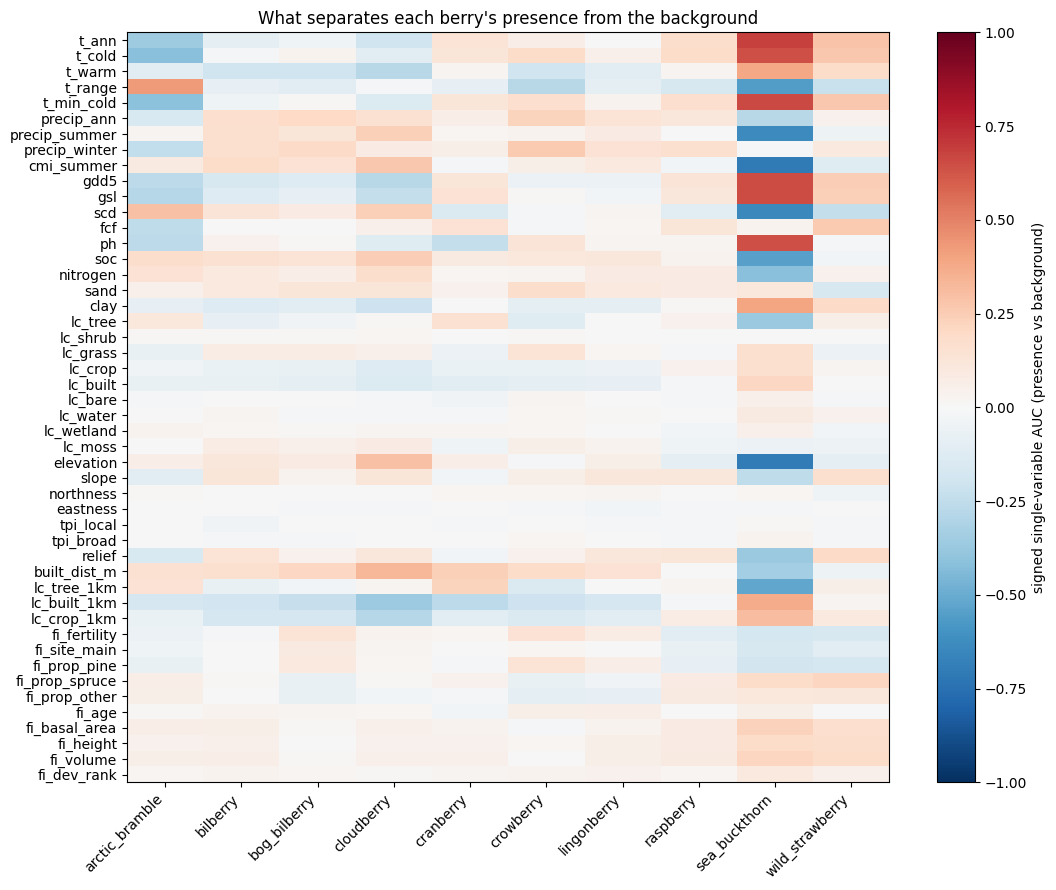

In [14]:
EDA_FEATURES = CLIM_DER_COLS + SOIL_COLS + LC_COLS + TOPO_COLS + HUMAN_COLS + FI_COLS
rows = []
for s in SPECIES_NAMES:
    y = data[f"gbif_y_{s}"]
    labelled = y >= 0
    for f in EDA_FEATURES:
        ok = labelled & data[f].notna()
        if ok.sum() > 100 and y[ok].nunique() == 2 and (y[ok] == 1).sum() >= 30:
            rows.append((s, f, 2 * (roc_auc_score(y[ok], data.loc[ok, f]) - 0.5)))
corr = pd.DataFrame(rows, columns=["species", "feature", "signed_auc"]).pivot(index="feature", columns="species", values="signed_auc").reindex(EDA_FEATURES)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.to_numpy(float), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
fig.colorbar(im, label="signed single-variable AUC (presence vs background)")
ax.set_title("What separates each berry's presence from the background")
plt.tight_layout()
plt.show()

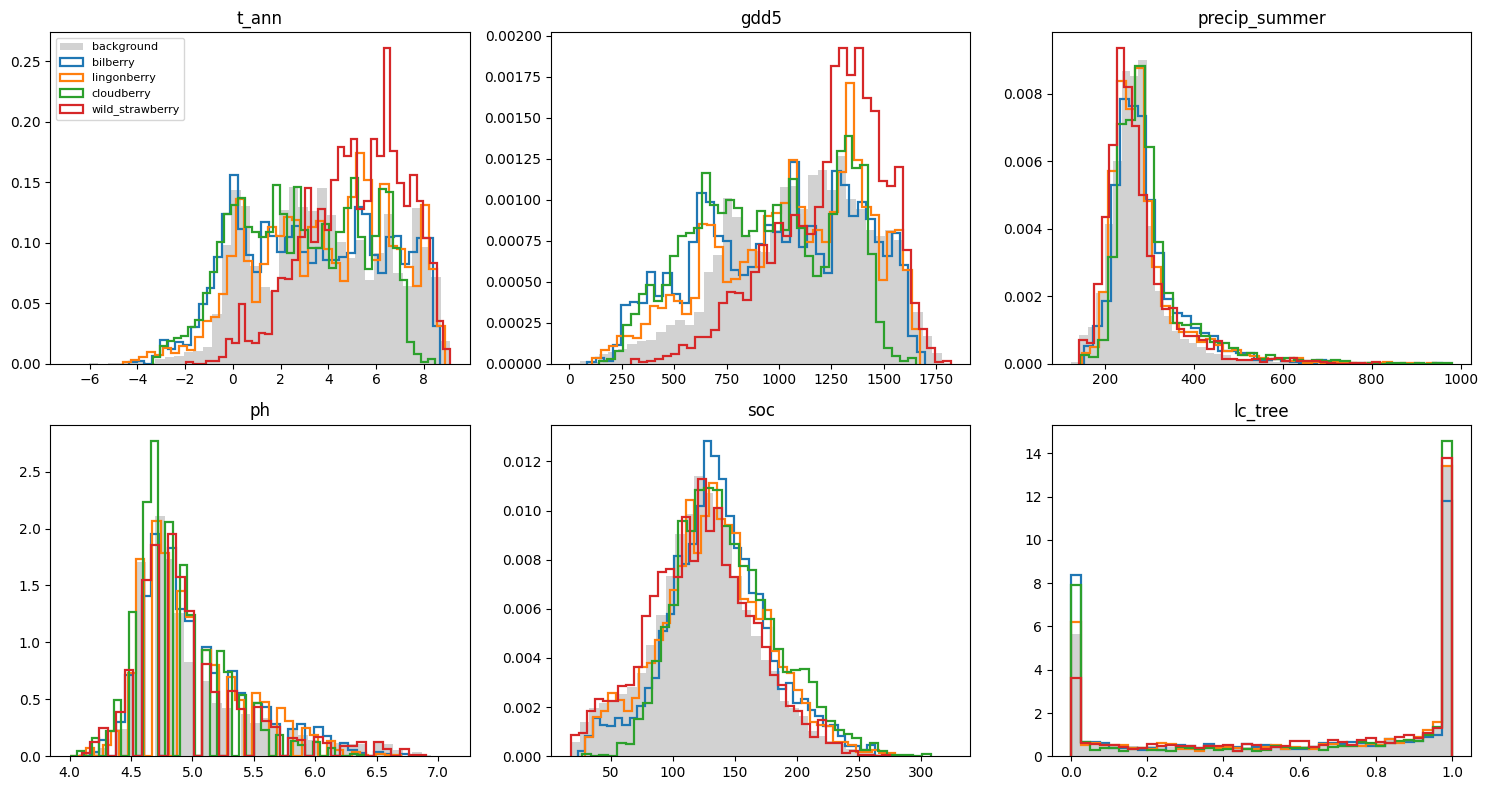

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.ravel(), ["t_ann", "gdd5", "precip_summer", "ph", "soc", "lc_tree"]):
    bg = data.loc[data[GBIF_COLS].max(axis=1) == 0, feat].dropna()
    ax.hist(bg, bins=40, density=True, alpha=0.35, color="grey", label="background")
    for s in ["bilberry", "lingonberry", "cloudberry", "wild_strawberry"]:
        v = data.loc[data[f"gbif_y_{s}"] == 1, feat].dropna()
        if len(v):
            ax.hist(v, bins=40, density=True, histtype="step", linewidth=1.6, label=s)
    ax.set_title(feat)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Preprocessing and tensors

* Skewed variables get a signed log; everything is standardised with **training-set statistics only**.
* Terrain (7 features) and human footprint (4 features) are separate input sources.
* Each input source has a **mask** (1 = data present). Missing values become 0 and the mask tells the network. This is how one model serves both Finland (with stand data) and the rest of the Nordics (without), and places where a raster has no value.
* Climate is kept as a **12-month × 4-channel sequence** (so the network can learn seasonal shape) plus the derived summary features.

In [16]:
SEQ_CHANNELS = CLIM_CHANNELS
LOG_COLS = {"soc", "nitrogen", "fi_volume", "precip_ann", "precip_summer", "precip_winter", "slope", "relief"}
MODALITIES = ["clim", "soil", "lc", "topo", "fi", "human"]    # order of the mask columns


class Preprocessor:
    def __init__(self):
        self.stats = {}
        self.seq_stats = {}

    @staticmethod
    def _tf(col, v):
        v = np.asarray(v, dtype=float)
        return np.sign(v) * np.log1p(np.abs(v)) if col in LOG_COLS else v

    def fit(self, df):
        for col in CLIM_DER_COLS + SOIL_COLS + TOPO_COLS + FI_COLS + HUMAN_COLS:
            v = self._tf(col, df[col].to_numpy())
            self.stats[col] = (float(np.nanmean(v)), float(np.nanstd(v)) or 1.0)
        for p in SEQ_CHANNELS:
            v = df[month_cols(p)].to_numpy(float)
            self.seq_stats[p] = (float(np.nanmean(v)), float(np.nanstd(v)) or 1.0)
        return self

    def _matrix(self, df, cols):
        return np.stack([(self._tf(c, df[c].to_numpy()) - self.stats[c][0]) / self.stats[c][1] for c in cols], axis=1)

    def transform(self, df):
        seq = np.stack([(df[month_cols(p)].to_numpy(float) - self.seq_stats[p][0]) / self.seq_stats[p][1] for p in SEQ_CHANNELS], axis=1)
        der = self._matrix(df, CLIM_DER_COLS)
        soil = self._matrix(df, SOIL_COLS)
        topo = self._matrix(df, TOPO_COLS)
        lc = df[LC_COLS].to_numpy(float)
        fi = self._matrix(df, FI_COLS)
        human = self._matrix(df, HUMAN_COLS)
        masks = np.stack([
            ~(np.isnan(seq).any((1, 2)) | np.isnan(der).any(1)),
            ~np.isnan(soil).any(1),
            ~np.isnan(lc).any(1),
            ~np.isnan(topo).any(1),
            ~np.isnan(fi[:, :1]).any(1),    # Finnish stand found (fertility class present)
            ~np.isnan(human).any(1),
        ], axis=1).astype("float32")
        out = {"seq": seq, "der": der, "soil": soil, "lc": lc, "topo": topo, "fi": fi, "human": human}
        out = {k: np.nan_to_num(v, nan=0.0).astype("float32") for k, v in out.items()}
        out["masks"] = masks
        return out

    def to_dict(self):
        return {"stats": self.stats, "seq_stats": self.seq_stats}

    @classmethod
    def from_dict(cls, d):
        p = cls()
        p.stats = {k: tuple(v) for k, v in d["stats"].items()}
        p.seq_stats = {k: tuple(v) for k, v in d["seq_stats"].items()}
        return p


LABEL_COLS = [f"y_{s}" for s in SPECIES_NAMES]
train_df = data[data["split"] == "train"].reset_index(drop=True)
val_df = data[data["split"] == "val"].reset_index(drop=True)
test_df = data[data["split"] == "test"].reset_index(drop=True)

pre = Preprocessor().fit(train_df)


def to_tensors(df):
    d = pre.transform(df)
    t = {k: torch.as_tensor(v) for k, v in d.items()}
    t["y"] = torch.as_tensor(df[LABEL_COLS].to_numpy(np.int64))             # training labels (rules or GBIF, see LABEL_MODE)
    t["gbif_y"] = torch.as_tensor(df[GBIF_COLS].to_numpy(np.int64))         # real records, used only for the reality check
    return t


T_train, T_val, T_test = to_tensors(train_df), to_tensors(val_df), to_tensors(test_df)
dims = {"seq_ch": len(SEQ_CHANNELS), "der": len(CLIM_DER_COLS), "soil": len(SOIL_COLS), "lc": len(LC_COLS), "topo": len(TOPO_COLS),
        "fi": len(FI_COLS), "human": len(HUMAN_COLS)}
print({k: tuple(v.shape) for k, v in T_train.items()})
print("share of training rows with each source present:", dict(zip(MODALITIES, T_train["masks"].mean(0).tolist())))

{'seq': (24042, 4, 12), 'der': (24042, 13), 'soil': (24042, 5), 'lc': (24042, 9), 'topo': (24042, 7), 'fi': (24042, 10), 'human': (24042, 4), 'masks': (24042, 6), 'y': (24042, 10), 'gbif_y': (24042, 10)}
share of training rows with each source present: {'clim': 0.9999583959579468, 'soil': 0.899883508682251, 'lc': 1.0, 'topo': 1.0, 'fi': 0.24527908861637115, 'human': 1.0}


## 7. Model architecture

```
climate (4 channels x 12 months) ──► circular 1-D CNN ─┐
climate summary (12)  ─────────────► MLP ──────────────┤
soil (pH, SOC, N, sand, clay) ─────► MLP  × mask ──────┤
land cover fractions (9) ──────────► MLP  × mask ──────┼─► concat ─► residual trunk ─► environment embedding e (128)
terrain: elevation, slope, aspect, valley/ridge (7) ► MLP × mask ┤                    │
human footprint: built-up distance, tree/built/crop share (4) ► MLP × mask ┤              │
Finnish stand attributes (10) ─────► MLP  × mask ──────┘                                   ▼
                                                      logit(species k) = ⟨ W·e , s_k ⟩ / √d + b_k
```

* **Shared trunk, per-species embedding `s_k`.** All berries share what "a good Nordic habitat" looks like; each species gets its own direction in that space. Rare species borrow strength from common ones.
* **Circular convolution over months** because December is next to January.
* **Missing-source tokens and modality dropout.** A missing source is replaced by a learned token, and during training the soil, land-cover, terrain, human-footprint and stand branches are randomly switched off, so predictions stay sensible when a source is unavailable.
* **Masked presence–background loss** with square-root class weighting (section 8).
* **Deep ensemble.** Several members with different seeds; the spread of their outputs is the model's uncertainty.
* **No coordinates as input.** Latitude and longitude are deliberately not features, so the model must explain a place by its environment and can be asked about *any* location.

In [17]:
class ClimateEncoder(nn.Module):
    def __init__(self, n_channels, n_derived, out_dim=96, p=0.1):
        super().__init__()
        self.conv1 = nn.Conv1d(n_channels, 32, 3, padding=1, padding_mode="circular")
        self.conv2 = nn.Conv1d(32, 64, 3, padding=1, padding_mode="circular")
        self.derived = nn.Sequential(nn.Linear(n_derived, 32), nn.GELU())
        self.out = nn.Sequential(nn.Linear(64 * 2 + 32, out_dim), nn.GELU(), nn.Dropout(p))

    def forward(self, seq, derived):
        h = F.gelu(self.conv1(seq))
        h = F.gelu(self.conv2(h))
        h = torch.cat([h.mean(-1), h.amax(-1), self.derived(derived)], dim=-1)
        return self.out(h)


class MLP(nn.Module):
    def __init__(self, d_in, d_out, hidden, p=0.1):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.LayerNorm(hidden), nn.GELU(), nn.Dropout(p), nn.Linear(hidden, d_out))

    def forward(self, x):
        return self.net(x)


class ResBlock(nn.Module):
    def __init__(self, d, p=0.1):
        super().__init__()
        self.block = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(p), nn.Linear(2 * d, d))

    def forward(self, x):
        return x + self.block(x)


class BerryNet(nn.Module):
    SIZES = {"soil": 48, "lc": 32, "topo": 16, "fi": 32, "human": 16}

    def __init__(self, dims, n_species, emb=128, p=0.15, modality_dropout=0.1):
        super().__init__()
        self.modality_dropout = modality_dropout
        self.clim = ClimateEncoder(dims["seq_ch"], dims["der"], 96, p)
        self.enc = nn.ModuleDict({
            "soil": MLP(dims["soil"], self.SIZES["soil"], 64, p),
            "lc": MLP(dims["lc"], self.SIZES["lc"], 32, p),
            "topo": MLP(dims["topo"], self.SIZES["topo"], 16, p),
            "fi": MLP(dims["fi"], self.SIZES["fi"], 48, p),
            "human": MLP(dims["human"], self.SIZES["human"], 16, p),
        })
        self.missing = nn.ParameterDict({k: nn.Parameter(torch.zeros(v)) for k, v in self.SIZES.items()})
        fused = 96 + sum(self.SIZES.values())
        self.trunk = nn.Sequential(nn.Linear(fused, 256), nn.GELU(), nn.Dropout(p), ResBlock(256, p), ResBlock(256, p), nn.LayerNorm(256), nn.Linear(256, emb))
        self.proj = nn.Linear(emb, emb)
        self.species_emb = nn.Parameter(torch.randn(n_species, emb) * 0.1)
        self.bias = nn.Parameter(torch.zeros(n_species))

    def encode(self, b):
        m = b["masks"]
        if self.training and self.modality_dropout > 0:
            drop = (torch.rand_like(m) < self.modality_dropout).float()
            drop[:, 0] = 0.0                      # never drop climate
            m = m * (1.0 - drop)
        parts = [self.clim(b["seq"], b["der"])]
        for i, name in enumerate(["soil", "lc", "topo", "fi", "human"], start=1):
            mi = m[:, i:i + 1]
            parts.append(mi * self.enc[name](b[name] * mi) + (1.0 - mi) * self.missing[name])
        return self.trunk(torch.cat(parts, dim=-1))

    def forward(self, b):
        e = self.encode(b)
        return self.proj(e) @ self.species_emb.T / math.sqrt(e.shape[-1]) + self.bias


print(sum(p.numel() for p in BerryNet(dims, len(SPECIES_NAMES)).parameters()), "parameters")

670506 parameters


## 8. Training

**Loss.** For each berry, binary cross-entropy over the rows that are labelled for it (`y` is 0 or 1; `-1` rows are skipped). In `gbif` mode presences are rare next to background, so positives are weighted by √(background ÷ presences), clipped to 1…10. In `rules` mode the labels are treated as real probabilities, so **no weighting is used** and the sigmoid of the output estimates the rule probability. Because background points are unlabelled rather than true absences, the output is a *relative* score; that is why section 10 turns it into a percentile index instead of calling it a probability.

**Early stopping** on the validation blocks' mean AUC. The test blocks are touched only in section 9.

member 0: best validation AUC 0.798 at epoch 35  (157s)
member 1: best validation AUC 0.801 at epoch 34  (149s)
member 2: best validation AUC 0.799 at epoch 41  (170s)
member 3: best validation AUC 0.797 at epoch 23  (113s)
member 4: best validation AUC 0.796 at epoch 33  (145s)


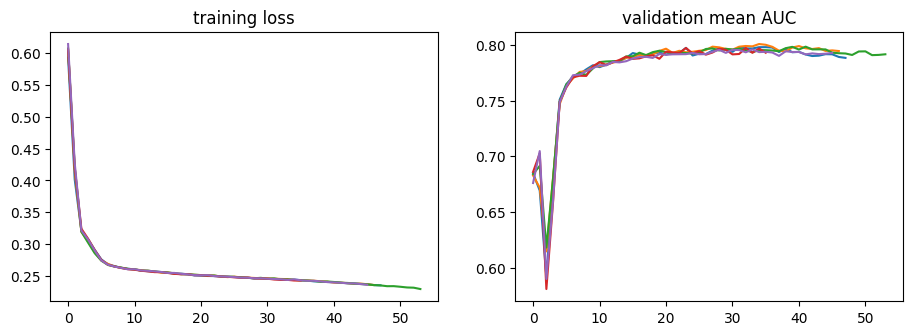

In [18]:
CFG = dict(epochs=6 if QUICK else 80, batch=512, lr=2e-3, wd=1e-2, patience=12, noise=0.05, emb=128, dropout=0.15,
           modality_dropout=0.10, members=2 if QUICK else 5, pos_weight=(LABEL_MODE == "gbif"))


def masked_bce(logits, y, pos_weight):
    mask = (y >= 0).float()
    loss = F.binary_cross_entropy_with_logits(logits, y.clamp(min=0).float(), reduction="none", pos_weight=pos_weight)
    return (loss * mask).sum() / mask.sum().clamp(min=1.0)


def class_weights(y, use=True):
    if not use:
        return torch.ones(y.shape[1])
    y = y.numpy()
    n_pos = (y == 1).sum(0)
    n_neg = (y == 0).sum(0)
    return torch.tensor(np.sqrt(n_neg / np.maximum(n_pos, 1)).clip(1, 10), dtype=torch.float32)


@torch.no_grad()
def predict_logits(model, tensors, batch=4096):
    model.eval()
    n = tensors["seq"].shape[0]
    out = []
    for i in range(0, n, batch):
        b = {k: v[i:i + batch].to(DEVICE) for k, v in tensors.items() if k not in ("y", "gbif_y")}
        out.append(model(b).cpu())
    return torch.cat(out).numpy()


def mean_auc(logits, y):
    y = y.numpy() if torch.is_tensor(y) else y
    aucs = []
    for k in range(y.shape[1]):
        m = y[:, k] >= 0
        if (y[m, k] == 1).sum() >= 5 and (y[m, k] == 0).sum() >= 5:
            aucs.append(roc_auc_score(y[m, k], logits[m, k]))
    return float(np.mean(aucs)) if aucs else float("nan")


def train_member(seed, train_t, val_t, cfg=CFG):
    seed_everything(seed)
    model = BerryNet(dims, len(SPECIES_NAMES), cfg["emb"], cfg["dropout"], cfg["modality_dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    n = train_t["seq"].shape[0]
    steps_per_epoch = math.ceil(n / cfg["batch"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=cfg["epochs"] * steps_per_epoch, pct_start=0.2)
    train_dev = {k: v.to(DEVICE) for k, v in train_t.items()}
    pos_weight = class_weights(train_t["y"], cfg["pos_weight"]).to(DEVICE)
    best = dict(auc=-1.0, state=copy.deepcopy(model.state_dict()), epoch=0)     # NaN validation AUC (too few positives) keeps the initial state
    history = []
    for epoch in range(cfg["epochs"]):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        total = 0.0
        for i in range(0, n, cfg["batch"]):
            idx = perm[i:i + cfg["batch"]]
            b = {k: v[idx] for k, v in train_dev.items()}
            for k in ("seq", "der", "soil", "topo", "fi", "human"):
                b[k] = b[k] + cfg["noise"] * torch.randn_like(b[k])     # small feature noise
            loss = masked_bce(model(b), b["y"], pos_weight)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            total += loss.item() * len(idx)
        val_auc = mean_auc(predict_logits(model, val_t), val_t["y"])
        history.append((epoch, total / n, val_auc))
        if np.nan_to_num(val_auc, nan=-1.0) > best["auc"]:
            best = dict(auc=val_auc, state=copy.deepcopy(model.state_dict()), epoch=epoch)
        if epoch - best["epoch"] >= cfg["patience"]:
            break
    model.load_state_dict(best["state"])
    return model, history, best


members, histories = [], []
for i in range(CFG["members"]):
    t0 = time.time()
    model, hist, best = train_member(SEED + i, T_train, T_val)
    members.append(model)
    histories.append(hist)
    print(f"member {i}: best validation AUC {best['auc']:.3f} at epoch {best['epoch']}  ({time.time() - t0:.0f}s)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for h in histories:
    ax[0].plot([x[1] for x in h])
    ax[1].plot([x[2] for x in h])
ax[0].set_title("training loss")
ax[1].set_title("validation mean AUC")
plt.show()

## 9. Evaluation on held-out geographic blocks

**In `rules` mode the first table measures how well the network recovers the written rules (labels drawn from 30 %, 50 % and 2 % probabilities cap the best possible AUC well below 1). It says nothing about real berries. The second table, scored against real GBIF records on the same held-out blocks, is the one that tests reality.**

Metrics per species, all computed on **test blocks the model never saw** and compared with two standard baselines trained on the same rows:

* **AUC**: chance that a random presence outranks a random background cell (0.5 = chance).
* **Boyce index**: whether higher scores really mean proportionally more presences (−1 to +1; the usual presence-only metric).
* **Recall at top 20 % of area**: share of test presences that fall in the best-scoring fifth of the background. Random guessing gives 0.20.
* **AP** depends on how many background points there are, so compare it only between models.

Read the baseline columns honestly: on small tabular data, gradient boosting often matches or beats a neural network. Use whichever the table says is best for your data.

In [19]:
def boyce_index(pos_scores, bg_scores, bins=20):
    edges = np.quantile(bg_scores, np.linspace(0, 1, bins + 1))
    edges[-1] += 1e-9
    P = np.histogram(pos_scores, edges)[0] / max(len(pos_scores), 1)
    ratio = P * bins                      # E is 1/bins by construction (bins are background quantiles)
    return float(spearmanr(np.arange(bins), ratio)[0])


def species_metrics(scores, y):
    # scores (n, K) and y (n, K) with -1 for unlabelled; presence vs background per species
    y = y.numpy() if torch.is_tensor(y) else y
    rows = []
    for k, name in enumerate(SPECIES_NAMES):
        pos, bg = scores[y[:, k] == 1, k], scores[y[:, k] == 0, k]
        if len(pos) < 5 or len(bg) < 5 or np.isnan(scores[:, k]).any():
            rows.append(dict(species=name, n_pos=len(pos), n_bg=len(bg)))
            continue
        labels = np.r_[np.ones(len(pos)), np.zeros(len(bg))]
        both = np.r_[pos, bg]
        rows.append(dict(species=name, n_pos=len(pos), n_bg=len(bg), auc=roc_auc_score(labels, both),
                         ap=average_precision_score(labels, both), boyce=boyce_index(pos, bg),
                         recall_top20=float((pos >= np.quantile(bg, 0.8)).mean())))
    return pd.DataFrame(rows).set_index("species")


def ensemble_logits(models, tensors):
    stack = np.stack([predict_logits(m, tensors) for m in models])
    return stack.mean(0), stack.std(0)


test_mean, test_std = ensemble_logits(members, T_test)
nn_metrics = species_metrics(test_mean, T_test["y"])

# ---- baselines: one model per species on the same rows, flat feature table
FLAT_COLS = CLIM_DER_COLS + SOIL_COLS + LC_COLS + TOPO_COLS + HUMAN_COLS + FI_COLS


def fit_baselines(train_df, test_df):
    out = {"logistic": np.full((len(test_df), len(SPECIES_NAMES)), np.nan), "boosting": np.full((len(test_df), len(SPECIES_NAMES)), np.nan)}
    for k, s in enumerate(SPECIES_NAMES):
        y = train_df[f"y_{s}"].to_numpy()
        m = y >= 0
        if (y[m] == 1).sum() < 20:
            continue
        lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
        lr.fit(train_df.loc[m, FLAT_COLS], y[m])
        out["logistic"][:, k] = lr.decision_function(test_df[FLAT_COLS])
        gb = HistGradientBoostingClassifier(max_depth=5, learning_rate=0.06, max_iter=300, class_weight="balanced", random_state=SEED)
        gb.fit(train_df.loc[m, FLAT_COLS], y[m])
        out["boosting"][:, k] = gb.decision_function(test_df[FLAT_COLS])
    return out


baseline_scores = fit_baselines(train_df, test_df)
lr_metrics = species_metrics(baseline_scores["logistic"], T_test["y"])
gb_metrics = species_metrics(baseline_scores["boosting"], T_test["y"])

comparison = pd.concat({"PyTorch ensemble": nn_metrics[["auc", "boyce", "recall_top20"]],
                        "Gradient boosting": gb_metrics[["auc", "boyce", "recall_top20"]],
                        "Logistic regression": lr_metrics[["auc", "boyce", "recall_top20"]]}, axis=1)
comparison.loc["MEAN"] = comparison.mean()
display(comparison.round(3))
display(nn_metrics[["n_pos", "n_bg"]])

# reality check against REAL GBIF records on the same held-out blocks (never used for training when LABEL_MODE == "rules")
real_metrics = species_metrics(test_mean, T_test["gbif_y"])
print("Agreement with real GBIF presence versus plant background on the test blocks (0.5 AUC = chance):")
display(real_metrics[["n_pos", "n_bg", "auc", "boyce", "recall_top20"]].round(3))

PyTorch ensemble                     Gradient boosting         \
                             auc  boyce recall_top20               auc  boyce   
species                                                                         
bilberry                   0.831  0.869        0.662             0.833  0.755   
lingonberry                0.823  0.884        0.646             0.834  0.762   
cloudberry                 0.834  0.144        0.780             0.838  0.313   
raspberry                  0.765  0.458        0.656             0.775  0.353   
bog_bilberry               0.851  0.184        0.842             0.864  0.380   
cranberry                  0.853  0.404        0.815             0.854  0.326   
crowberry                  0.838  0.429        0.771             0.834  0.271   
wild_strawberry            0.831  0.556        0.824             0.839  0.525   
arctic_bramble             0.797  0.198        0.724             0.813  0.194   
sea_buckthorn              0.745  0.146        0.643             0.788  0.542   
MEAN                       0.817  0.427        0.736             0.827  0.442   

                             Logistic regression                      
                recall_top20                 auc  boyce recall_top20  
species                                                               
bilberry               0.765               0.802  0.957        0.593  
lingonberry            0.674               0.783  0.984        0.585  
cloudberry             0.780               0.825  0.599        0.758  
raspberry              0.677               0.700  0.651        0.519  
bog_bilberry           0.839               0.820  0.827        0.715  
cranberry              0.804               0.822  0.398        0.786  
crowberry              0.773               0.792  0.814        0.674  
wild_strawberry        0.844               0.822  0.736        0.771  
arctic_bramble         0.727               0.773  0.675        0.664  
sea_buckthorn          0.684               0.750  0.700        0.625  
MEAN                   0.757               0.789  0.734        0.669

,n_pos,n_bg
species,,
bilberry,987,4671
lingonberry,1159,4499
cloudberry,400,5258
raspberry,285,5373
bog_bilberry,564,5094
cranberry,439,5219
crowberry,432,5226
wild_strawberry,454,5204
arctic_bramble,333,5325


Agreement with real GBIF presence versus plant background on the test blocks (0.5 AUC = chance):


,n_pos,n_bg,auc,boyce,recall_top20
species,,,,,
bilberry,526,2283,0.437,-0.498,0.202
lingonberry,600,2274,0.567,0.407,0.338
cloudberry,473,2318,0.648,0.948,0.359
raspberry,509,2298,0.578,0.759,0.273
bog_bilberry,457,2302,0.607,0.803,0.278
cranberry,422,2313,0.553,0.415,0.244
crowberry,493,2284,0.488,-0.071,0.142
wild_strawberry,348,2306,0.501,-0.019,0.201
arctic_bramble,324,2329,0.716,0.840,0.534


,source,auc_drop
1,soil,0.107715
2,land cover / forest,0.087832
0,climate,0.037340
5,human footprint,0.009464
4,Finnish stand data,0.003132
3,terrain,0.001227


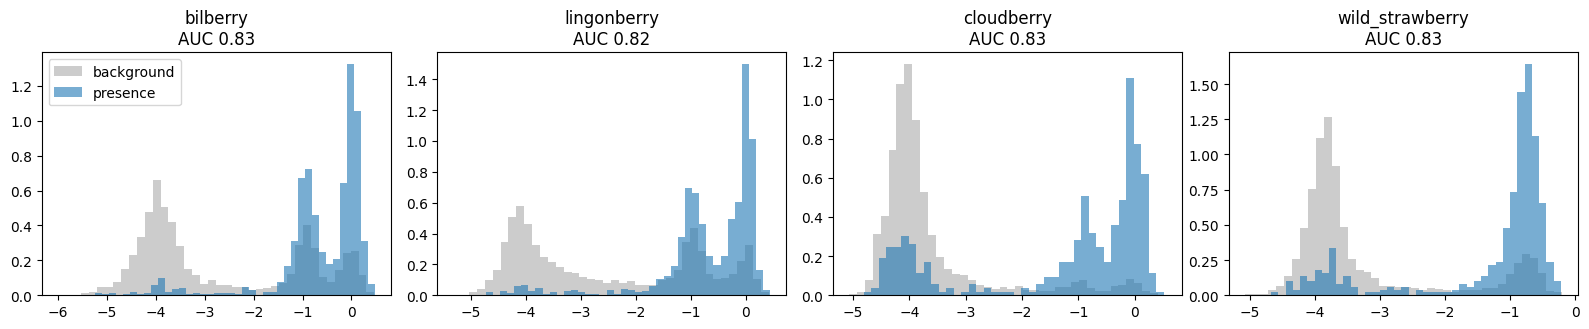

In [20]:
# ---- which input source matters? shuffle one source at a time on the test blocks and measure the AUC drop
def permutation_importance(models, tensors, groups, seed=SEED):
    # groups: name -> (input keys to shuffle, index of that source in the mask columns)
    g = torch.Generator().manual_seed(seed)
    base = mean_auc(ensemble_logits(models, tensors)[0], tensors["y"])
    rows = []
    for name, (keys, mask_col) in groups.items():
        perm = torch.randperm(tensors["seq"].shape[0], generator=g)
        shuffled = {k: (v[perm] if k in keys else v) for k, v in tensors.items()}
        masks = tensors["masks"].clone()
        masks[:, mask_col] = tensors["masks"][perm, mask_col]     # the mask travels with the shuffled values
        shuffled["masks"] = masks
        rows.append((name, base - mean_auc(ensemble_logits(models, shuffled)[0], tensors["y"])))
    return pd.DataFrame(rows, columns=["source", "auc_drop"]).sort_values("auc_drop", ascending=False)


importance = permutation_importance(members, T_test, {
    "climate": (["seq", "der"], 0), "soil": (["soil"], 1), "land cover / forest": (["lc"], 2),
    "terrain": (["topo"], 3), "Finnish stand data": (["fi"], 4), "human footprint": (["human"], 5)})
display(importance)

# ---- score distributions: presence vs background for four species
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, s in zip(axes, ["bilberry", "lingonberry", "cloudberry", "wild_strawberry"]):
    k = SPECIES_NAMES.index(s)
    y = T_test["y"].numpy()[:, k]
    ax.hist(test_mean[y == 0, k], bins=40, density=True, alpha=0.4, color="grey", label="background")
    ax.hist(test_mean[y == 1, k], bins=40, density=True, alpha=0.6, label="presence")
    auc_text = f"AUC {nn_metrics.loc[s, 'auc']:.2f}" if "auc" in nn_metrics.columns and pd.notna(nn_metrics.loc[s, "auc"]) else "AUC n/a"
    ax.set_title(f"{s}\n{auc_text}")
axes[0].legend()
plt.tight_layout()
plt.show()

## 10. Predicting for a location

In `rules` mode the output also lists `rule_probability` (what the written rules say for that place) next to `model_probability` (what the network learned from them); both are **assumption-based**, not measured chances.

Three things are built from the trained ensemble:

1. **Suitability index** per species, 0 to 100: the percentile of the place's score within the target-group background of that species (90 = more suitable than 90 % of typical recorded places). It is a ranking aid, not a probability of finding berries.
2. **Uncertainty**: the standard deviation of the ensemble members' scores, and an **out-of-distribution flag** if the place's climate, soil and elevation lie far outside the training data.
3. A readable **profile** of the place: soil type, weather, forest type.

Predictions need network access (the same sources as training).

In [21]:
# ---- bundle everything needed at prediction time
logits_trainval = np.concatenate([ensemble_logits(members, T_train)[0], ensemble_logits(members, T_val)[0]])
y_trainval = np.concatenate([T_train["y"].numpy(), T_val["y"].numpy()])
bg_sorted = {s: np.sort(logits_trainval[y_trainval[:, k] == 0, k]) for k, s in enumerate(SPECIES_NAMES)}


def ood_features(tensors):
    return torch.cat([tensors["der"], tensors["soil"], tensors["topo"]], dim=1).numpy()


Z = ood_features(T_train)
ood_mean = Z.mean(0)
ood_icov = np.linalg.inv(np.cov(Z, rowvar=False) + 1e-3 * np.eye(Z.shape[1]))


def mahalanobis(Zq):
    d = Zq - ood_mean
    return np.sqrt(np.einsum("ij,jk,ik->i", d, ood_icov, d))


ood_threshold = float(np.quantile(mahalanobis(Z), 0.995))

BUNDLE = dict(members=members, pre=pre, dims=dims, cfg=CFG, species=SPECIES_NAMES, bg_sorted=bg_sorted,
              ood_mean=ood_mean, ood_icov=ood_icov, ood_threshold=ood_threshold, platt={}, label_mode=LABEL_MODE)


def save_bundle(bundle, path=ARTIFACTS / "berry_model.pt"):
    torch.save(dict(state_dicts=[m.state_dict() for m in bundle["members"]], pre=bundle["pre"].to_dict(), dims=bundle["dims"],
                    cfg=bundle["cfg"], species=bundle["species"], bg_sorted=bundle["bg_sorted"], ood_mean=bundle["ood_mean"],
                    ood_icov=bundle["ood_icov"], ood_threshold=bundle["ood_threshold"], platt=bundle["platt"], label_mode=bundle["label_mode"]), path)
    print("saved", path)


def load_bundle(path=ARTIFACTS / "berry_model.pt"):
    blob = torch.load(path, map_location=DEVICE, weights_only=False)
    cfg = blob["cfg"]
    ms = []
    for sd in blob["state_dicts"]:
        m = BerryNet(blob["dims"], len(blob["species"]), cfg["emb"], cfg["dropout"], cfg["modality_dropout"]).to(DEVICE)
        m.load_state_dict(sd)
        m.eval()
        ms.append(m)
    return dict(members=ms, pre=Preprocessor.from_dict(blob["pre"]), dims=blob["dims"], cfg=cfg, species=blob["species"],
                bg_sorted=blob["bg_sorted"], ood_mean=blob["ood_mean"], ood_icov=blob["ood_icov"],
                ood_threshold=blob["ood_threshold"], platt=blob.get("platt", {}), label_mode=blob.get("label_mode", "gbif"))


save_bundle(BUNDLE)

saved artifacts/berry_model.pt


In [22]:
def predict_points(points, bundle=None):
    # points: DataFrame with lat, lon. Returns (features, scores, std, suitability index 0-100, ood flag)
    bundle = bundle or BUNDLE
    feats = extract_all_features(points)
    if feats["t_ann"].isna().any():
        raise ValueError("No climate data for at least one point (open sea or outside CHELSA coverage).")
    d = bundle["pre"].transform(feats)
    tensors = {k: torch.as_tensor(v) for k, v in d.items()}
    stack = np.stack([predict_logits(m, tensors) for m in bundle["members"]])
    mean, std = stack.mean(0), stack.std(0)
    index = np.stack([100.0 * np.searchsorted(bundle["bg_sorted"][s], mean[:, k]) / len(bundle["bg_sorted"][s])
                      for k, s in enumerate(bundle["species"])], axis=1)
    Zq = torch.cat([tensors["der"], tensors["soil"], tensors["topo"]], dim=1).numpy()
    d_ood = np.sqrt(np.einsum("ij,jk,ik->i", Zq - bundle["ood_mean"], bundle["ood_icov"], Zq - bundle["ood_mean"]))
    return feats, mean, std, index, d_ood > bundle["ood_threshold"]


# ---------------------------------------------------------------- readable description of a place
FI_FERTILITY = {1: "herb-rich forest (lehto)", 2: "herb-rich heath (OMT)", 3: "mesic heath (MT)", 4: "sub-xeric heath (VT)",
                5: "xeric heath (CT)", 6: "barren heath (ClT)", 7: "rock or sand", 8: "fell or summit forest"}
FI_SITE = {1: "mineral-soil heath", 2: "spruce mire", 3: "pine mire", 4: "open bog", 5: "rich fen"}


def usda_texture(sand, clay):
    silt = 100 - sand - clay
    if silt + 1.5 * clay < 15: return "sand"
    if silt + 1.5 * clay >= 15 and silt + 2 * clay < 30: return "loamy sand"
    if (7 <= clay < 20 and sand > 52 and silt + 2 * clay >= 30) or (clay < 7 and silt < 50 and silt + 2 * clay >= 30): return "sandy loam"
    if 7 <= clay < 27 and 28 <= silt < 50 and sand <= 52: return "loam"
    if (silt >= 50 and 12 <= clay < 27) or (50 <= silt < 80 and clay < 12): return "silt loam"
    if silt >= 80 and clay < 12: return "silt"
    if 20 <= clay < 35 and silt < 28 and sand > 45: return "sandy clay loam"
    if 27 <= clay < 40 and 20 < sand <= 45: return "clay loam"
    if 27 <= clay < 40 and sand <= 20: return "silty clay loam"
    if clay >= 35 and sand > 45: return "sandy clay"
    if clay >= 40 and silt >= 40: return "silty clay"
    if clay >= 40 and sand <= 45 and silt < 40: return "clay"
    return "loam"


def describe_place(r):
    lines = []
    if not np.isnan(r["ph"]):
        acid = "very acid" if r["ph"] < 4.5 else "acid" if r["ph"] < 5.5 else "slightly acid" if r["ph"] < 6.5 else "near-neutral or alkaline"
        organic = ("peat or very organic topsoil" if r["soc"] >= 120 else "humus-rich" if r["soc"] >= 60
                   else "moderately organic" if r["soc"] >= 20 else "low in organic matter")
        lines.append(f"Soil (SoilGrids, 5-15 cm): pH {r['ph']:.1f} ({acid}); {organic} (organic carbon {r['soc']:.0f} g/kg); "
                     f"{usda_texture(r['sand'], r['clay'])} texture (sand {r['sand']:.0f} %, clay {r['clay']:.0f} %)")
    else:
        lines.append("Soil: no SoilGrids value here (water, ice or built-up)")
    lines.append(f"Climate (CHELSA 1981-2010 normal, about 1 km): mean {r['t_ann']:.1f} C a year, coldest month {r['t_cold']:.1f} C, "
                 f"warmest {r['t_warm']:.1f} C; {r['gdd5']:.0f} degree-days above 5 C; growing season {r['gsl']:.0f} days; "
                 f"snow cover {r['scd']:.0f} days a year; rain {r['precip_ann']:.0f} mm a year ({r['precip_summer']:.0f} mm in June to August); "
                 f"summer moisture index {r['cmi_summer']:.0f} (negative = water deficit)")
    if not np.isnan(r["lc_tree"]):
        if r["lc_tree"] >= 0.6: forest = "closed forest"
        elif r["lc_tree"] >= 0.3: forest = "open or mixed forest"
        elif r["lc_wetland"] >= 0.4: forest = "mire or wetland"
        elif r["lc_shrub"] >= 0.4: forest = "shrubland"
        elif r["lc_crop"] >= 0.4: forest = "farmland"
        elif r["lc_built"] >= 0.3: forest = "built-up"
        else: forest = "open land"
        lines.append(f"Land cover (ESA WorldCover, about 200 m around): {forest} (trees {r['lc_tree']:.0%}, wetland {r['lc_wetland']:.0%}, "
                     f"shrub {r['lc_shrub']:.0%}, moss and lichen {r['lc_moss']:.0%}, water {r['lc_water']:.0%})")
    if not np.isnan(r["fi_fertility"]):
        mix = "pine-dominated" if r["fi_prop_pine"] >= 0.65 else "spruce-dominated" if r["fi_prop_spruce"] >= 0.65 else "broadleaf-dominated" if r["fi_prop_other"] >= 0.5 else "mixed"
        site = FI_SITE.get(int(r["fi_site_main"]), "unknown class") if pd.notna(r["fi_site_main"]) else "unknown class"
        lines.append(f"Finnish stand data: {FI_FERTILITY.get(int(r['fi_fertility']), 'unknown site')} on {site}; "
                     f"{mix} forest, mean age {r['fi_age']:.0f} years, basal area {r['fi_basal_area']:.0f} m2/ha")
    if pd.notna(r["slope"]):
        position = ("in a hollow or valley floor (cold air and water collect)" if r["tpi_broad"] < -5 else
                    "on a ridge or hilltop" if r["tpi_broad"] > 5 else "on level or gently varying ground")
        facing = "" if r["slope"] < 1 else (", facing " + ("north" if r["northness"] > 0.5 else "south" if r["northness"] < -0.5 else "east or west"))
        lines.append(f"Terrain (Copernicus DEM 30 m): elevation {r['elevation']:.0f} m, slope {r['slope']:.1f} degrees{facing}; {position}; "
                     f"relief {r['relief']:.0f} m within about 300 m")
    if pd.notna(r["lc_tree_1km"]):
        near = "no built-up surface within 500 m" if r["built_dist_m"] >= 500 else f"nearest built-up surface about {r['built_dist_m']:.0f} m away"
        lines.append(f"Surroundings (500 m): trees {r['lc_tree_1km']:.0%}, built-up {r['lc_built_1km']:.0%}, cropland {r['lc_crop_1km']:.0%}; {near}")
    return "\n".join(lines)


def predict_location(lat, lon, bundle=None, top=None):
    bundle = bundle or BUNDLE
    feats, mean, std, index, ood = predict_points(pd.DataFrame({"lat": [lat], "lon": [lon]}), bundle)
    print(f"Location {lat:.4f}, {lon:.4f}\n" + describe_place(feats.iloc[0]))
    if ood[0]:
        print("\nWARNING: this place's climate, soil or elevation is unusual compared with the training data; treat the result with extra caution.")
    rule_p = rule_probability(feats).iloc[0]
    res = pd.DataFrame({
        "species": bundle["species"],
        "finnish": [SPECIES[s]["fi"] if s in SPECIES else "" for s in bundle["species"]],
        "suitability_index": index[0].round(0),
        "score": mean[0].round(2),
        "uncertainty": std[0].round(2),
        "rule_probability": [float(rule_p[s]) if s in rule_p.index else np.nan for s in bundle["species"]],
    })
    if bundle.get("label_mode") == "rules":
        res["model_probability"] = (1 / (1 + np.exp(-mean[0]))).round(3)       # what the network learned from the rule labels
    for s, (a, b) in bundle.get("platt", {}).items():
        res.loc[res["species"] == s, "p_find_calibrated"] = 1 / (1 + np.exp(-(a * mean[0, bundle["species"].index(s)] + b)))
    res = res.sort_values("suitability_index", ascending=False).reset_index(drop=True)
    return res.head(top) if top else res


def predict_map(species, west, south, east, north, step=0.05, bundle=None):
    bundle = bundle or BUNDLE
    lats = np.arange(south, north + 1e-9, step)
    lons = np.arange(west, east + 1e-9, step)
    grid = pd.DataFrame([(la, lo) for la in lats for lo in lons], columns=["lat", "lon"])
    feats, mean, std, index, ood = predict_points(grid, bundle)
    k = bundle["species"].index(species)
    img = index[:, k].reshape(len(lats), len(lons))
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(img, origin="lower", extent=(west, east, south, north), cmap="YlGn", vmin=0, vmax=100, aspect="auto")
    fig.colorbar(im, label=f"{species} suitability index (0-100)")
    ax.set_title(f"{species}: relative habitat suitability (estimate, not a harvest forecast)")
    plt.show()
    return grid.assign(suitability_index=index[:, k], uncertainty=std[:, k], ood=ood)

### Examples (run these after training)

* Oulu (northern Ostrobothnia), a southern Finland forest, Lapland fell, a Swedish and a Norwegian location.
* A 0.05° map around Oulu: each grid point triggers the same data fetches as training, so keep maps small or reduce resolution.

In [23]:
examples = {"Oulu, Finland": (65.01, 25.47), "Nuuksio, southern Finland": (60.30, 24.50), "Kilpisjarvi fell, Lapland": (69.05, 20.80),
            "Dalarna, Sweden": (60.60, 15.60), "Trondheim area, Norway": (63.35, 10.40)}
for name, (la, lo) in examples.items():
    print("=" * 80)
    print(name)
    display(predict_location(la, lo, top=6))

Oulu, Finland
  climate_chelsa: 1/1 new places


TypeError: invalid path or file: ('/vsicurl/https://copernicus-dem-30m.s3.amazonaws.com/Copernicus_DSM_COG_10_N65_00_E025_00_DEM/Copernicus_DSM_COG_10_N65_00_E025_00_DEM.tif',)

In [ ]:
oulu_map = predict_map("bilberry", west=25.0, south=64.8, east=26.0, north=65.3, step=0.05)

## 11. Optional: calibrate with true presence/absence field data

The index above ranks places. To turn it into a **probability of finding berries** (and to measure real-world accuracy), you need records where observers say *found* or *not found*, such as the BerryFinder app's 1 m² plot surveys or any partner's monitoring data.

Put them in a CSV with the columns `lat, lon, species, found` (1 = berries found, 0 = properly searched and none found), and the function below fits a per-species Platt calibration on the model's score and reports AUC and Brier score. **Hold out part of this data for the report** (it does so with a spatial split) and expect honest numbers to be lower than your hopes until you have a few hundred records per species.

In [ ]:
def calibrate_with_field_data(csv_path, bundle=None):
    bundle = bundle or BUNDLE
    field = pd.read_csv(csv_path)
    feats, mean, std, index, ood = predict_points(field[["lat", "lon"]], bundle)
    field["block"] = (np.floor(field["lat"] / BLOCK_DEG).astype(int).astype(str) + "_" + np.floor(field["lon"] / BLOCK_DEG).astype(int).astype(str))
    rows = []
    for s in bundle["species"]:
        m = (field["species"] == s).to_numpy()
        if m.sum() < 40 or field.loc[m, "found"].nunique() < 2:
            continue
        x = mean[m, bundle["species"].index(s)].reshape(-1, 1)
        y = field.loc[m, "found"].to_numpy()
        blocks = field.loc[m, "block"].to_numpy()
        ub = np.unique(blocks)
        np.random.default_rng(SEED).shuffle(ub)
        test_blocks = set(ub[: max(1, len(ub) // 4)])
        te = np.array([b in test_blocks for b in blocks])
        if len(np.unique(y[~te])) < 2 or len(np.unique(y[te])) < 2:
            continue
        platt = LogisticRegression(C=1e6).fit(x[~te], y[~te])
        p = platt.predict_proba(x[te])[:, 1]
        rows.append(dict(species=s, n=int(m.sum()), auc_heldout=roc_auc_score(y[te], p), brier_heldout=float(np.mean((p - y[te]) ** 2)),
                         base_rate=float(y.mean())))
        bundle["platt"][s] = (float(platt.coef_[0, 0]), float(platt.intercept_[0]))
    return pd.DataFrame(rows).set_index("species") if rows else pd.DataFrame()


# example: report = calibrate_with_field_data("field_observations.csv"); save_bundle(BUNDLE)

## 12. Limits, and how to make it better

* **Rule labels are assumptions.** In `rules` mode the network reproduces the rules in the labelling script (section 4b) (30 % where conditions are right, 50 % if undisturbed). Compare the reality-check table in section 9 with chance; where it is near 0.5 the rules are not capturing real distributions, and edit them. Built-up distance is only a proxy for roads. Wild strawberry and sea buckthorn rules have no source behind them.
* **Presence-only labels (`gbif` mode).** The index says where a species is *recorded relative to other plants*. It cannot tell a place with a few berries from one with a bumper crop, and it knows nothing about this year's weather. Yield forecasting needs yearly monitoring data, such as Luke's, and the season's weather, with a model trained on those.
* **Climate is a 30-year average at about 1 km.** CHELSA separates valleys from fells, but it still cannot see a single hillside's microclimate (aspect, cold-air pockets) and it knows nothing about this year's weather. Terrain features from the 30 m elevation model (slope, aspect, valley or ridge position) are included now, but they cannot see forest cover or soil moisture at that scale. National FMI, MET Norway and SMHI grids can replace CHELSA where finer data exists; only `fetch_climate()` needs to change.
* **Forest type is rich only in Finland.** Elsewhere the model sees land-cover fractions, not species or age of the forest. Add national forest inventories (SLU, NIBIO) as another masked branch, exactly like the Finnish stand branch.
* **Observer bias is reduced, not removed.** Target-group background helps, but areas nobody visits are under-sampled. Treat very remote predictions with caution; the out-of-distribution flag helps.
* **Check before relying on it.** Look at section 9: if a species' held-out AUC is near 0.5 or its Boyce index is low or negative, the model has not learned it; do not use it for that species.
* **Licences.** GBIF records keep their own licence and citation requirements (cite the GBIF occurrence download or use the GBIF download API for a DOI when you publish). Copernicus DEM and CHELSA are free and open (credit them).

**Next steps that move accuracy the most:** (1) true presence/absence from field surveys and section 11; (2) real road geometry (OpenStreetMap) in place of the built-up proxy, and this year's weather for seasonal forecasts; (3) satellite vegetation indices (Sentinel-2 or MODIS NDVI) and snow-cover duration as new branches; (4) national forest inventories; (5) tune `CFG` and the block size with spatial cross-validation.